# Floor 2 — 2018 vs 2019 Comparative Analysis

**Dataset:** CU-BEMS Smart Building Energy & Indoor Environmental Data (Kaggle)
**Files analysed:** `data/2018Floor2.csv` and `data/2019Floor2.csv`
**Scope:** one floor (Floor 2), 4 zones, 1-minute sampling, power + indoor-environment sensors.

This notebook mirrors the Floor 6 analysis so the two floors can be compared directly. It asks
what changed on Floor 2 between 2018 and 2019: how much energy was used, *when* it was used
(load profiles, weekday/weekend, occupied/after-hours), how the zones and end-uses split,
how the indoor climate behaved, and which days and units are unusual.

Floor 2 differs from Floor 6 in two ways that drive the whole analysis:

* **Zone 2 carries 14 of the floor's 16 AC units** — thirteen small units plus one large one.
  Unit-level behaviour therefore matters more here than zone-level totals (Section 13).
* **Zone 3 has no AC at all** — it is the floor's only un-cooled zone, which makes it a useful
  natural control when judging whether the cooled zones are overcooled.

---

## Read this first — data coverage caveats

* **2018 file:** 1 Jul – 31 Dec 2018 only (the dataset starts mid-year).
* **2019 file:** full calendar year.
* **Environment sensors stop reporting in Sep 2018 and only return in Mar 2019.** Zone 4 has no
  sensor data at all in 2018. Any temperature/humidity/lux comparison is therefore restricted to
  **Apr–Dec 2019**, and Section 10 masks months with low coverage automatically.
* **The large AC units are 28–42 % missing in Jan–Feb 2019.** The dip in floor energy in those
  months is a reporting gap, not a real saving. Section 7 flags it.
* **`z2_AC11` reads 0.0 for all 18 months**, and `z2_AC12` / `z2_AC14` are almost always off.
  They are reported, not silently dropped.

Throughout, *occupied* means **weekday 08:00–16:59**. The dataset has no occupancy sensor —
this is a proxy inferred from the load profile in Section 8, and every conclusion that uses it
is phrased accordingly.

## 1. Setup

Imports the three libraries used throughout (`pandas` for tabular work, `numpy` for numeric
helpers, `matplotlib` for charts), sets display options, and locates the `data/` folder. The path
check works whether the notebook is launched from a `workspace/` subfolder or from the repo root.

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 170)
plt.rcParams['figure.figsize'] = (12, 4.5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

DATA_DIR = next(p for p in [Path('../data'), Path('data')] if p.exists())
print('Using data folder:', DATA_DIR.resolve())

FILE_2018 = DATA_DIR / '2018Floor2.csv'
FILE_2019 = DATA_DIR / '2019Floor2.csv'
FLOOR = 'Floor 2'

Using data folder: /Applications/A_Y3S1/smart analytics/is4001-g1-smart-building/data


## 2. Load & inspect

Read each CSV **as-is first**, before any cleaning, so we can see exactly what we were handed:
shape, column list, dtypes and a numeric summary.

In [2]:
raw18 = pd.read_csv(FILE_2018)
raw19 = pd.read_csv(FILE_2019)

print(f'2018 file : {raw18.shape[0]:,} rows x {raw18.shape[1]} columns')
print(f'2019 file : {raw19.shape[0]:,} rows x {raw19.shape[1]} columns')
print('Identical column layout in both years:', list(raw18.columns) == list(raw19.columns))

raw18.head(3)

2018 file : 264,960 rows x 37 columns
2019 file : 525,600 rows x 37 columns
Identical column layout in both years: True


,Date,z1_AC1(kW),z1_Light(kW),z1_Plug(kW),z1_S1(degC),z1_S1(RH%),z1_S1(lux),z2_AC1(kW),z2_AC2(kW),z2_AC3(kW),z2_AC4(kW),z2_AC5(kW),z2_AC6(kW),z2_AC7(kW),z2_AC8(kW),z2_AC9(kW),z2_AC10(kW),z2_AC11(kW),z2_AC12(kW),z2_AC13(kW),z2_AC14(kW),z2_Light(kW),z2_Plug(kW),z2_S1(degC),z2_S1(RH%),z2_S1(lux),z3_Light(kW),z3_Plug(kW),z3_S1(degC),z3_S1(RH%),z3_S1(lux),z4_AC1(kW),z4_Light(kW),z4_Plug(kW),z4_S1(degC),z4_S1(RH%),z4_S1(lux)
0,2018-07-01 00:00:00,0.0,0.01,0.15,28.36,58.93,0.0,1.08,0.0,0.0,0.0,1.29,1.26,0.87,0.92,0.96,1.07,0.0,0.0,0.0,0.0,0.0,0.10,28.85,64.89,0.0,0.01,0.32,29.30,68.22,0.0,0.0,0.0,0.0,NaN,NaN,NaN
1,2018-07-01 00:01:00,0.0,0.01,0.15,28.36,58.91,0.0,1.07,0.0,0.0,0.0,1.30,1.24,0.88,0.91,0.97,1.06,0.0,0.0,0.0,0.0,0.0,0.10,28.85,64.89,0.0,0.01,0.32,29.30,68.21,0.0,0.0,0.0,0.0,NaN,NaN,NaN
2,2018-07-01 00:02:00,0.0,0.01,0.15,28.36,58.94,0.0,0.88,0.0,0.0,0.0,1.09,1.03,0.74,0.75,0.82,0.88,0.0,0.0,0.0,0.0,0.0,0.09,28.85,64.89,0.0,0.01,0.28,29.29,68.24,0.0,0.0,0.0,0.0,NaN,NaN,NaN


In [3]:
dtype_table = pd.DataFrame({
    '2018 dtype': raw18.dtypes.astype(str),
    '2019 dtype': raw19.dtypes.astype(str),
})
print('All dtypes identical across years:',
      (dtype_table['2018 dtype'] == dtype_table['2019 dtype']).all())
display(dtype_table.T)

raw18.describe().T

All dtypes identical across years: True


,Date,z1_AC1(kW),z1_Light(kW),z1_Plug(kW),z1_S1(degC),z1_S1(RH%),z1_S1(lux),z2_AC1(kW),z2_AC2(kW),z2_AC3(kW),z2_AC4(kW),z2_AC5(kW),z2_AC6(kW),z2_AC7(kW),z2_AC8(kW),z2_AC9(kW),z2_AC10(kW),z2_AC11(kW),z2_AC12(kW),z2_AC13(kW),z2_AC14(kW),z2_Light(kW),z2_Plug(kW),z2_S1(degC),z2_S1(RH%),z2_S1(lux),z3_Light(kW),z3_Plug(kW),z3_S1(degC),z3_S1(RH%),z3_S1(lux),z4_AC1(kW),z4_Light(kW),z4_Plug(kW),z4_S1(degC),z4_S1(RH%),z4_S1(lux)
2018 dtype,object,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
2019 dtype,object,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


,count,mean,std,min,25%,50%,75%,max
z1_AC1(kW),264486.0,8.424212,13.214355,0.00,0.00,0.00,18.9475,59.61
z1_Light(kW),264525.0,2.982769,3.836481,0.00,0.01,0.01,7.9700,11.11
z1_Plug(kW),264523.0,1.087545,1.394516,0.00,0.16,0.22,2.3100,5.21
z1_S1(degC),101930.0,26.064966,2.214908,21.26,23.60,26.77,27.7400,30.90
z1_S1(RH%),101930.0,56.786173,3.926308,46.28,54.12,56.54,59.3300,72.80
z1_S1(lux),101930.0,29.771853,35.210304,0.00,0.00,2.00,65.0000,96.00
z2_AC1(kW),264374.0,4.910338,7.643438,0.00,0.00,1.02,6.0900,50.72
z2_AC2(kW),264520.0,0.661284,0.528410,0.00,0.23,0.98,1.1700,1.52
z2_AC3(kW),264520.0,0.453653,0.436305,0.00,0.00,0.72,0.8800,1.19
z2_AC4(kW),264520.0,0.509778,0.489992,0.00,0.00,0.81,0.9900,1.39


### 2.1 Turn the column names into metadata

Column names follow the structure `zone_channel(unit)` (e.g. `z2_AC7(kW)`). A regex pulls those
three pieces apart, and the result builds every column list used later (all power columns, all AC
columns, all temperature columns) instead of hard-coding names.

The pivot table underneath is a one-glance audit of the floor: Zone 2 holds 14 AC units, Zone 3
has none, and every zone has one environment sensor.

In [4]:
col_meta = pd.DataFrame({'column': raw18.columns[1:]})          # skip 'Date'
col_meta = pd.concat([
    col_meta,
    col_meta['column'].str.extract(r'^(?P<zone>z\d+)_(?P<channel>.+?)\((?P<unit>.+)\)$'),
], axis=1)

col_meta['kind'] = np.where(col_meta['unit'] == 'kW', 'power', 'sensor')
col_meta['end_use'] = col_meta['channel'].map(
    lambda c: 'Cooling (AC)' if c.startswith('AC')
    else ('Lighting' if c == 'Light' else ('Plug load' if c == 'Plug' else 'Sensor'))
)

display(col_meta)

col_meta.pivot_table(index='zone', columns='end_use', values='column',
                     aggfunc='count', fill_value=0)

,column,zone,channel,unit,kind,end_use
0,z1_AC1(kW),z1,AC1,kW,power,Cooling (AC)
1,z1_Light(kW),z1,Light,kW,power,Lighting
2,z1_Plug(kW),z1,Plug,kW,power,Plug load
3,z1_S1(degC),z1,S1,degC,sensor,Sensor
4,z1_S1(RH%),z1,S1,RH%,sensor,Sensor
5,z1_S1(lux),z1,S1,lux,sensor,Sensor
6,z2_AC1(kW),z2,AC1,kW,power,Cooling (AC)
7,z2_AC2(kW),z2,AC2,kW,power,Cooling (AC)
8,z2_AC3(kW),z2,AC3,kW,power,Cooling (AC)
9,z2_AC4(kW),z2,AC4,kW,power,Cooling (AC)


end_use,Cooling (AC),Lighting,Plug load,Sensor
zone,,,,
z1,1,1,1,3
z2,14,1,1,3
z3,0,1,1,3
z4,1,1,1,3


In [5]:
power_cols  = col_meta.query("kind == 'power'")['column'].tolist()
sensor_cols = col_meta.query("kind == 'sensor'")['column'].tolist()
ac_cols     = col_meta.query("end_use == 'Cooling (AC)'")['column'].tolist()
light_cols  = col_meta.query("end_use == 'Lighting'")['column'].tolist()
plug_cols   = col_meta.query("end_use == 'Plug load'")['column'].tolist()
temp_cols   = col_meta.query("unit == 'degC'")['column'].tolist()
rh_cols     = col_meta.query("unit == 'RH%'")['column'].tolist()
lux_cols    = col_meta.query("unit == 'lux'")['column'].tolist()
zone_ids    = sorted(col_meta['zone'].unique())

print('power columns  :', len(power_cols), '| AC:', len(ac_cols),
      '| lighting:', len(light_cols), '| plug:', len(plug_cols))
print('sensor columns :', len(sensor_cols), '(temp', len(temp_cols),
      '/ RH', len(rh_cols), '/ lux', len(lux_cols), ')')
print('zones          :', zone_ids)
print('AC units       :', ac_cols)

power columns  : 24 | AC: 16 | lighting: 4 | plug: 4
sensor columns : 12 (temp 4 / RH 4 / lux 4 )
zones          : ['z1', 'z2', 'z3', 'z4']
AC units       : ['z1_AC1(kW)', 'z2_AC1(kW)', 'z2_AC2(kW)', 'z2_AC3(kW)', 'z2_AC4(kW)', 'z2_AC5(kW)', 'z2_AC6(kW)', 'z2_AC7(kW)', 'z2_AC8(kW)', 'z2_AC9(kW)', 'z2_AC10(kW)', 'z2_AC11(kW)', 'z2_AC12(kW)', 'z2_AC13(kW)', 'z2_AC14(kW)', 'z4_AC1(kW)']


## 3. Data quality

Everything downstream depends on this section. Five checks are run:

1. **Unparseable timestamps** — parsed with `errors='coerce'` so junk rows become `NaT` and can be
   dropped rather than crashing the notebook.
2. **Continuity** — with 1-minute sampling the row count must equal `(max − min) / 1 min + 1`.
   Expected vs actual rows, duplicate timestamps and step sizes prove whether the series has holes.
3. **Missing values** — `%` missing per column per year, split into power vs environment columns.
4. **Outage windows** — *when* the gaps happened, as contiguous runs of `NaN` of at least an hour.
5. **Zeros** — a 0.0 kW reading is a measurement ("off"), not a gap, and is counted separately.
   This is how the permanently-dead `z2_AC11` is identified.

In [6]:
def clean_year(df, label):
    """Parse dates safely, drop junk rows, sort, and report what happened."""
    d = df.copy()
    d['Date'] = pd.to_datetime(d['Date'], errors='coerce')   # NaT instead of exception
    bad = d['Date'].isna()
    print(f'{label}: {int(bad.sum())} row(s) with an unparseable Date -> dropped')
    if bad.any():
        print(d.loc[bad].head())
    d = d.loc[~bad].sort_values('Date').reset_index(drop=True)
    d['year'] = d['Date'].dt.year
    lo, hi = d['Date'].min(), d['Date'].max()
    print(f'{label}: {len(d):,} valid rows | {lo} -> {hi}')
    return d

df18 = clean_year(raw18, '2018')
df19 = clean_year(raw19, '2019')

2018: 0 row(s) with an unparseable Date -> dropped
2018: 264,960 valid rows | 2018-07-01 00:00:00 -> 2018-12-31 23:59:00
2019: 0 row(s) with an unparseable Date -> dropped
2019: 525,600 valid rows | 2019-01-01 00:00:00 -> 2019-12-31 23:59:00


In [7]:
def continuity_stats(d, label):
    """Row-count arithmetic that proves whether the 1-minute series is complete."""
    t = d['Date']
    expected = int((t.max() - t.min()).total_seconds() // 60) + 1
    steps = t.diff().dropna()
    return pd.Series({
        'rows': len(d),
        'start': t.min(),
        'end': t.max(),
        'expected rows (1-min)': expected,
        'missing minutes': expected - len(d),
        'duplicate timestamps': int(t.duplicated().sum()),
        'steps != 1 min': int((steps != pd.Timedelta(minutes=1)).sum()),
        'largest gap': steps.max(),
    }, name=label)

display(pd.concat([continuity_stats(df18, '2018'),
                   continuity_stats(df19, '2019')], axis=1))

,2018,2019
rows,264960,525600
start,2018-07-01 00:00:00,2019-01-01 00:00:00
end,2018-12-31 23:59:00,2019-12-31 23:59:00
expected rows (1-min),264960,525600
missing minutes,0,0
duplicate timestamps,0,0
steps != 1 min,0,0
largest gap,0 days 00:01:00,0 days 00:01:00


### 3.1 Missing values by column

Both years side by side, sorted by the worse year. The pattern is the headline data-quality
result for Floor 2:

* **Power columns are mostly clean**, except the three large AC units which lose a large share of
  Jan–Feb 2019 (visible in the monthly breakdown below).
* **Environment sensors are missing a third to a half of all rows** — they are restricted to
  live windows in Section 10.

In [8]:
cols_to_check = power_cols + sensor_cols

missing = pd.DataFrame({
    'missing 2018 (%)': df18[cols_to_check].isna().mean().mul(100).round(2),
    'missing 2019 (%)': df19[cols_to_check].isna().mean().mul(100).round(2),
})
missing['worst'] = missing.max(axis=1)
missing = missing.sort_values('worst', ascending=False).drop(columns='worst')
display(missing)

rollup = pd.DataFrame({
    '2018 (%)': [df18[power_cols].isna().mean().mean() * 100,
                 df18[sensor_cols].isna().mean().mean() * 100],
    '2019 (%)': [df19[power_cols].isna().mean().mean() * 100,
                 df19[sensor_cols].isna().mean().mean() * 100],
}, index=['power columns', 'environment sensors'])
display(rollup.round(2))

,missing 2018 (%),missing 2019 (%)
z4_S1(lux),100.00,19.65
z4_S1(RH%),100.00,19.65
z4_S1(degC),100.00,19.65
z2_S1(lux),61.63,18.46
z2_S1(RH%),61.63,18.46
z2_S1(degC),61.63,18.46
z1_S1(lux),61.53,21.23
z1_S1(RH%),61.53,21.23
z1_S1(degC),61.53,21.23
z3_S1(lux),61.30,19.49


,2018 (%),2019 (%)
power columns,0.18,0.87
environment sensors,71.11,19.71


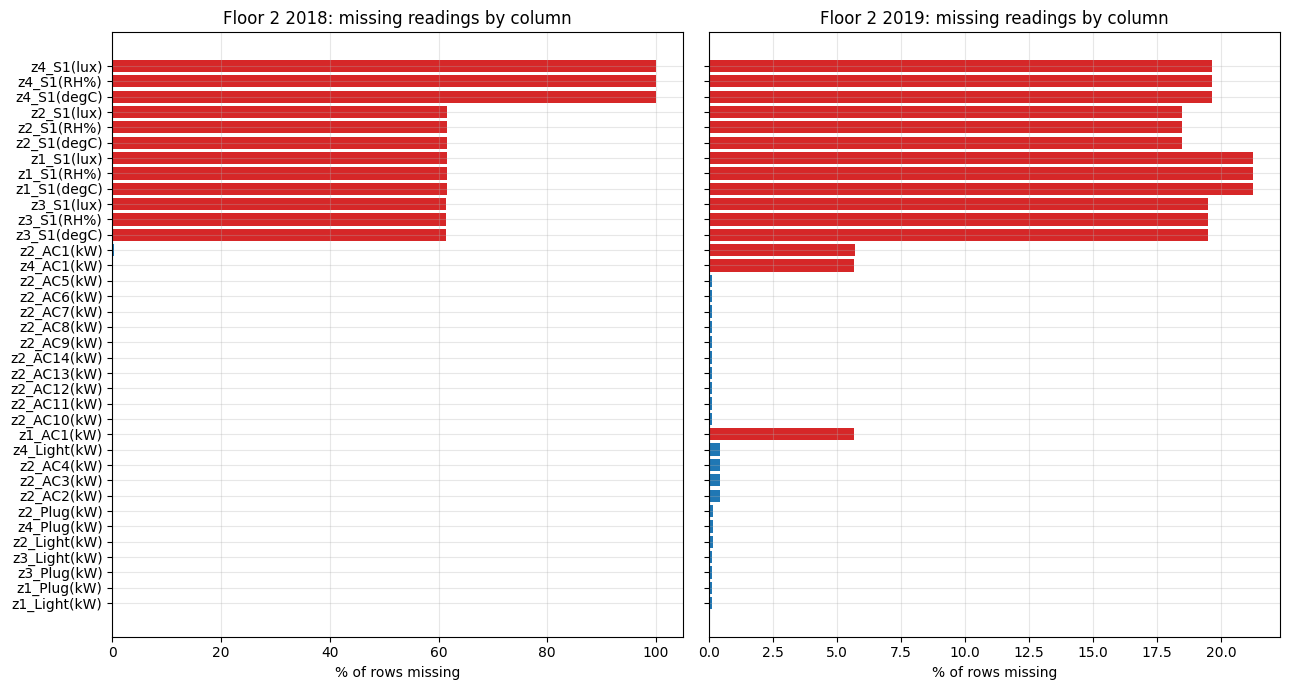

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
for ax, (label, d) in zip(axes, [('2018', df18), ('2019', df19)]):
    pct = d[cols_to_check].isna().mean().mul(100).sort_values()
    ax.barh(pct.index, pct.values,
            color=['#d62728' if v > 5 else '#1f77b4' for v in pct.values])
    ax.set_title(f'{FLOOR} {label}: missing readings by column')
    ax.set_xlabel('% of rows missing')
plt.tight_layout()
plt.show()

In [10]:
# WHEN are the power columns missing?  Monthly view of the three large AC units.
big_ac = ['z1_AC1(kW)', 'z2_AC1(kW)', 'z4_AC1(kW)']
df_all_tmp = pd.concat([df18, df19], ignore_index=True)
miss_by_month = (df_all_tmp[big_ac].isna()
                 .groupby(df_all_tmp['Date'].dt.to_period('M')).mean().mul(100).round(1))
display(miss_by_month)
print('Months where any large AC unit is >20% missing -> excluded from energy comparisons:')
print(list(miss_by_month.index[(miss_by_month > 20).any(axis=1)].astype(str)))

,z1_AC1(kW),z2_AC1(kW),z4_AC1(kW)
Date,,,
2018-07,0.0,0.1,0.0
2018-08,0.7,0.8,0.7
2018-09,0.2,0.3,0.2
2018-10,0.2,0.2,0.2
2018-11,0.0,0.0,0.1
2018-12,0.0,0.0,0.1
2019-01,28.0,28.1,28.0
2019-02,41.6,41.6,41.6
2019-03,0.0,0.0,0.0


Months where any large AC unit is >20% missing -> excluded from energy comparisons:
['2019-01', '2019-02']


### 3.2 Sensor outage windows

Percentages say *how much* is missing; this says *when*. For every environment sensor the code
finds contiguous runs of `NaN` and keeps runs of at least an hour. This is the evidence behind
the "sensors died in Sep 2018 and returned in Mar 2019" finding, and it justifies the masking in
Section 10.

In [11]:
def nan_runs(ts, series, min_minutes=60):
    """Contiguous stretches of missing values, as start / end / length."""
    isna = series.isna()
    if not isna.any():
        return pd.DataFrame(columns=['start', 'end', 'minutes'])
    block = (isna != isna.shift()).cumsum()
    runs = (pd.DataFrame({'isna': isna.values, 'block': block.values, 't': ts.values})
            .loc[lambda x: x['isna']]
            .groupby('block')['t']
            .agg(['min', 'max', 'size'])
            .rename(columns={'min': 'start', 'max': 'end', 'size': 'minutes'}))
    return runs[runs['minutes'] >= min_minutes].sort_values('minutes', ascending=False)

rows = []
for label, d in [('2018', df18), ('2019', df19)]:
    for c in sensor_cols + big_ac:
        r = nan_runs(d['Date'], d[c])
        if len(r):
            top = r.iloc[0]
            rows.append({'year': label, 'column': c, 'outage runs >=1h': len(r),
                         'longest outage (days)': round(top['minutes'] / 1440, 1),
                         'from': top['start'], 'to': top['end']})
outages = pd.DataFrame(rows).sort_values('longest outage (days)', ascending=False)
display(outages.head(20))

,year,column,outage runs >=1h,longest outage (days),from,to
9,2018,z4_S1(degC),1,184.0,2018-07-01 00:00:00,2018-12-31 23:59:00
11,2018,z4_S1(lux),1,184.0,2018-07-01 00:00:00,2018-12-31 23:59:00
10,2018,z4_S1(RH%),1,184.0,2018-07-01 00:00:00,2018-12-31 23:59:00
7,2018,z3_S1(RH%),5,110.3,2018-09-12 16:10:00,2018-12-31 23:59:00
1,2018,z1_S1(RH%),5,110.3,2018-09-12 16:17:00,2018-12-31 23:59:00
8,2018,z3_S1(lux),5,110.3,2018-09-12 16:10:00,2018-12-31 23:59:00
0,2018,z1_S1(degC),5,110.3,2018-09-12 16:17:00,2018-12-31 23:59:00
6,2018,z3_S1(degC),5,110.3,2018-09-12 16:10:00,2018-12-31 23:59:00
5,2018,z2_S1(lux),7,110.3,2018-09-12 15:51:00,2018-12-31 23:59:00
4,2018,z2_S1(RH%),7,110.3,2018-09-12 15:51:00,2018-12-31 23:59:00


### 3.3 Zeros are *measurements*, not gaps

Share of readings equal to exactly 0.0 kW per power column. High zero-rates are expected for
lighting (off overnight and at weekends). A unit at **100 % zeros is not "efficient" — it is dead
or unmetered**, and must be excluded from per-unit comparisons.

In [12]:
zero_pct = pd.DataFrame({
    'zero 2018 (%)': (df18[power_cols] == 0).mean().mul(100).round(1),
    'zero 2019 (%)': (df19[power_cols] == 0).mean().mul(100).round(1),
}).sort_values('zero 2019 (%)', ascending=False)
display(zero_pct)

DEAD_UNITS = zero_pct.index[(zero_pct['zero 2018 (%)'] > 99) &
                            (zero_pct['zero 2019 (%)'] > 99)].tolist()
print('Permanently off / unmetered channels:', DEAD_UNITS)
print('Total NaNs still present after cleaning (both years):',
      int(df18[cols_to_check].isna().sum().sum() + df19[cols_to_check].isna().sum().sum()))

,zero 2018 (%),zero 2019 (%)
z2_AC11(kW),99.8,99.9
z2_AC14(kW),97.9,99.6
z2_AC12(kW),99.1,99.3
z2_AC13(kW),94.4,92.1
z4_AC1(kW),71.8,70.1
z1_AC1(kW),68.2,66.0
z2_Light(kW),62.7,63.7
z4_Light(kW),60.3,63.2
z2_AC8(kW),48.4,60.7
z2_AC10(kW),48.0,60.7


Permanently off / unmetered channels: ['z2_AC11(kW)', 'z2_AC12(kW)']
Total NaNs still present after cleaning (both years): 3624790


## 4. Time features

The timestamp is decomposed into the calendar parts every later analysis groups by:

| Feature | Built with | Used for |
|---|---|---|
| `date` | `dt.date` | daily kWh totals, anomaly detection |
| `hour` | `dt.hour` | load profiles |
| `month` | `dt.month` | monthly year-on-year comparison |
| `day_of_week` / `day_name` | `dt.dayofweek` / `dt.day_name()` | weekday vs weekend |
| `is_weekend` | `day_of_week >= 5` | occupancy proxy |
| `is_occupied` | Mon–Fri and hour 8–16 | occupied vs after-hours split |
| `is_holiday` | Thai public-holiday list | removes false "anomalies" in Section 12 |
| `is_night` | hour >= 22 or hour < 5 | the deep-night baseload used in Section 13 |

The building is in Bangkok, so Thai public holidays are listed explicitly — without them, every
holiday looks like an anomalous low-energy day.

In [13]:
THAI_HOLIDAYS = pd.to_datetime([
    # 2018 (Jul-Dec only, matching the file coverage)
    '2018-07-27', '2018-07-30', '2018-08-13', '2018-10-15', '2018-10-23',
    '2018-12-05', '2018-12-10', '2018-12-31',
    # 2019
    '2019-01-01', '2019-02-19', '2019-04-08', '2019-04-15', '2019-04-16',
    '2019-05-06', '2019-05-20', '2019-06-03', '2019-07-16', '2019-07-17',
    '2019-08-12', '2019-10-14', '2019-10-23', '2019-12-05', '2019-12-10',
    '2019-12-30', '2019-12-31',
]).date

def add_time_features(d):
    out = d.copy()
    dt = out['Date']
    out['date']        = dt.dt.date
    out['hour']        = dt.dt.hour
    out['month']       = dt.dt.month
    out['day_of_week'] = dt.dt.dayofweek          # Monday = 0 ... Sunday = 6
    out['day_name']    = dt.dt.day_name()
    out['is_weekend']  = out['day_of_week'] >= 5
    out['is_holiday']  = out['date'].isin(THAI_HOLIDAYS)
    out['is_occupied'] = (out['day_of_week'] < 5) & out['hour'].between(8, 16) & ~out['is_holiday']
    out['is_night']    = (out['hour'] >= 22) | (out['hour'] < 5)
    return out

df18 = add_time_features(df18)
df19 = add_time_features(df19)
print('occupied minutes 2018:', int(df18['is_occupied'].sum()),
      '| 2019:', int(df19['is_occupied'].sum()))

occupied minutes 2018: 66420 | 2019: 131760


## 5. Energy derivation (kW → kWh)

Every power column is an **instantaneous kW reading sampled each minute**, so

$$E_{\text{kWh}} = \sum_{\text{rows}} \frac{P_{\text{kW}}}{60}$$

Derived columns: per-zone totals, a floor total, and the end-use split (cooling / lighting /
plug), each as both kW and kWh.

In [14]:
zone_power_cols = {z: [c for c in power_cols if c.startswith(z + '_')] for z in zone_ids}

def add_energy(d):
    out = d.copy()
    for z, cols in zone_power_cols.items():
        out[f'{z}_total_kW'] = out[cols].sum(axis=1, min_count=1) if cols else np.nan
    zone_tot = [f'{z}_total_kW' for z in zone_ids]
    out['floor_total_kW'] = out[zone_tot].sum(axis=1, min_count=1)
    out['cooling_kW']  = out[ac_cols].sum(axis=1, min_count=1)
    out['lighting_kW'] = out[light_cols].sum(axis=1, min_count=1)
    out['plug_kW']     = out[plug_cols].sum(axis=1, min_count=1)
    for c in zone_tot + ['floor_total_kW', 'cooling_kW', 'lighting_kW', 'plug_kW']:
        out[c + 'h'] = out[c] / 60          # 'z1_total_kW' -> 'z1_total_kWh'
    out['floor_kWh'] = out['floor_total_kW'] / 60
    return out

df18 = add_energy(df18)
df19 = add_energy(df19)
df_all = pd.concat([df18, df19], ignore_index=True)
print('combined rows:', f'{len(df_all):,}')
df_all[['Date', 'floor_total_kW', 'cooling_kW', 'lighting_kW', 'plug_kW']].head(3)

combined rows: 790,560


,Date,floor_total_kW,cooling_kW,lighting_kW,plug_kW
0,2018-07-01 00:00:00,8.04,7.45,0.02,0.57
1,2018-07-01 00:01:00,8.02,7.43,0.02,0.57
2,2018-07-01 00:02:00,6.73,6.19,0.02,0.52


## 6. Year-level comparison

Headline totals per year. **Read the `days with data` row first:** 2018 covers only Jul–Dec
(184 days) while 2019 covers the full year, so raw totals are not like-for-like. The comparable
rows are `kWh per day`, the end-use split, and the per-zone breakdown.

In [15]:
def yearly_summary(d, label):
    days = d['date'].nunique()
    s = {
        'days with data': days,
        'total floor energy (kWh)': d['floor_kWh'].sum(),
        'avg demand (kW)': d['floor_total_kW'].mean(),
        'cooling (kWh)': d['cooling_kWh'].sum(),
        'lighting (kWh)': d['lighting_kWh'].sum(),
        'plug load (kWh)': d['plug_kWh'].sum(),
    }
    for z in zone_ids:
        s[f'{z} (kWh)'] = d[f'{z}_total_kWh'].sum()
    s['kWh per day'] = d['floor_kWh'].sum() / days
    s['cooling share (%)'] = d['cooling_kWh'].sum() / d['floor_kWh'].sum() * 100
    s['lighting share (%)'] = d['lighting_kWh'].sum() / d['floor_kWh'].sum() * 100
    s['plug share (%)'] = d['plug_kWh'].sum() / d['floor_kWh'].sum() * 100
    return pd.Series(s, name=label)

summary = pd.concat([yearly_summary(df18, '2018'), yearly_summary(df19, '2019')], axis=1)
summary['delta %'] = (summary['2019'] - summary['2018']) / summary['2018'] * 100
display(summary.round(1))

,2018,2019,delta %
days with data,184.0,365.0,98.4
total floor energy (kWh),124021.3,240974.7,94.3
avg demand (kW),28.1,27.5,-2.1
cooling (kWh),95455.7,189431.9,98.5
lighting (kWh),21259.4,37358.1,75.7
plug load (kWh),7306.2,14184.7,94.1
z1 (kWh),55079.7,103283.6,87.5
z2 (kWh),49968.2,107397.0,114.9
z3 (kWh),3947.4,7274.5,84.3
z4 (kWh),15026.1,23019.6,53.2


,2018,2019,delta %
count,264577.00,525113.00,98.47
mean,28.13,27.53,-2.10
std,31.24,33.35,6.74
min,0.00,0.00,NaN
25%,7.45,5.16,-30.74
50%,8.38,8.63,2.98
75%,60.31,40.60,-32.68
max,146.81,130.38,-11.19


,2018 mean (kW),2019 mean (kW),delta %
z1_total_kW,12.49,11.80,-5.52
z2_total_kW,11.33,12.27,8.30
z3_total_kW,0.90,0.83,-7.14
z4_total_kW,3.41,2.63,-22.80


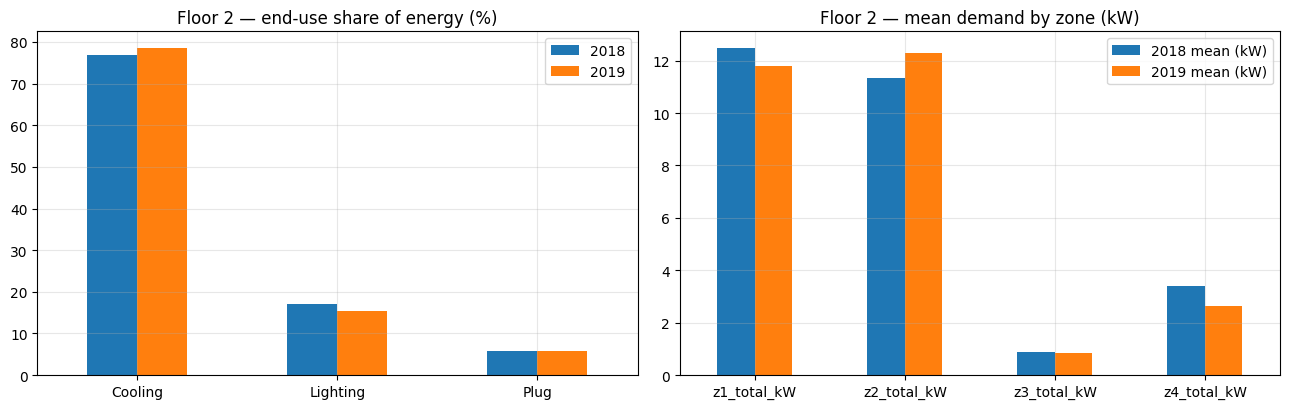

In [16]:
desc = pd.concat({'2018': df18['floor_total_kW'].describe(),
                  '2019': df19['floor_total_kW'].describe()}, axis=1)
desc['delta %'] = ((desc['2019'] - desc['2018']) / desc['2018'].replace(0, np.nan) * 100)
display(desc.round(2))

zone_means = pd.DataFrame({
    '2018 mean (kW)': df18[[f'{z}_total_kW' for z in zone_ids]].mean(),
    '2019 mean (kW)': df19[[f'{z}_total_kW' for z in zone_ids]].mean(),
})
zone_means['delta %'] = (zone_means['2019 mean (kW)'] - zone_means['2018 mean (kW)']) \
                        / zone_means['2018 mean (kW)'] * 100
display(zone_means.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
end_use = pd.DataFrame({
    '2018': [df18['cooling_kWh'].sum(), df18['lighting_kWh'].sum(), df18['plug_kWh'].sum()],
    '2019': [df19['cooling_kWh'].sum(), df19['lighting_kWh'].sum(), df19['plug_kWh'].sum()],
}, index=['Cooling', 'Lighting', 'Plug'])
(end_use / end_use.sum() * 100).plot(kind='bar', ax=axes[0])
axes[0].set_title(f'{FLOOR} — end-use share of energy (%)'); axes[0].tick_params(axis='x', rotation=0)
zone_means[['2018 mean (kW)', '2019 mean (kW)']].plot(kind='bar', ax=axes[1])
axes[1].set_title(f'{FLOOR} — mean demand by zone (kW)'); axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

## 7. Monthly year-on-year comparison

The fair comparison. Energy is normalised to **kWh per day** so partial months do not look like
collapses in consumption. Months where a large AC unit was more than 20 % missing (Jan–Feb 2019)
are flagged — their totals understate reality.

In [17]:
zone_kwh_cols = [f'{z} kWh' for z in zone_ids]

monthly = (df_all.groupby(['year', 'month'])
           .agg(days=('date', 'nunique'),
                floor_kWh=('floor_kWh', 'sum'),
                cooling_kWh=('cooling_kWh', 'sum'),
                **{f'{z} kWh': (f'{z}_total_kWh', 'sum') for z in zone_ids}))
monthly['kWh per day'] = monthly['floor_kWh'] / monthly['days']

suspect = set(miss_by_month.index[(miss_by_month > 20).any(axis=1)].astype(str))
monthly['data gap?'] = [f'{y}-{m:02d}' in suspect for y, m in monthly.index]
display(monthly.round(1))

days  floor_kWh  cooling_kWh   z1 kWh   z2 kWh  z3 kWh  z4 kWh  kWh per day  data gap?
year month                                                                                        
2018 7        31    23966.4      18580.0  10109.5  10198.6   701.7  2956.7        773.1      False
     8        31    22188.1      16709.0  10639.7   8070.0   719.1  2759.3        715.7      False
     9        30    20840.1      15543.5  10030.9   7424.0   731.4  2653.9        694.7      False
     10       31    20177.7      15562.6   8584.1   8493.1   667.9  2432.6        650.9      False
     11       30    19408.0      15308.7   8275.7   8073.8   582.0  2476.6        646.9      False
     12       31    17440.9      13751.9   7439.8   7708.7   545.4  1747.1        562.6      False
2019 1        31    15039.1      10889.7   6078.6   7063.3   579.9  1317.3        485.1       True
     2        28    14501.2      10914.2   5289.0   7531.9   510.8  1169.5        517.9       True
     3        31    22830.8      18645.0   8942.7  10977.4   594.9  2315.8        736.5      False
     4        30    20735.2      16944.2   8327.9   9670.8   610.5  2126.0        691.2      False
     5        31    23326.1      19180.1   9960.3  10212.5   643.2  2510.1        752.5      False
     6        30    21108.0      16839.4   9616.0   8965.5   642.8  1883.7        703.6      False
     7        31    21902.5      17121.7  10854.6   8372.2   678.0  1997.8        706.5      False
     8        31    21689.0      16926.3  10322.0   8701.6   678.3  1987.1        699.6      False
     9        30    22205.1      17158.7  10730.4   8906.6   646.0  1922.2        740.2      False
     10       31    21114.2      16683.0   8633.8   9709.1   566.3  2205.1        681.1      False
     11       30    19552.3      15159.3   7885.9   9128.6   566.3  1971.5        651.7      False
     12       31    16971.2      12970.2   6642.4   8157.7   557.5  1613.6        547.5      False

,2018,2019,delta %
month,,,
1,NaN,485.1,NaN
2,NaN,517.9,NaN
3,NaN,736.5,NaN
4,NaN,691.2,NaN
5,NaN,752.5,NaN
6,NaN,703.6,NaN
7,773.1,706.5,-8.6
8,715.7,699.6,-2.2
9,694.7,740.2,6.5


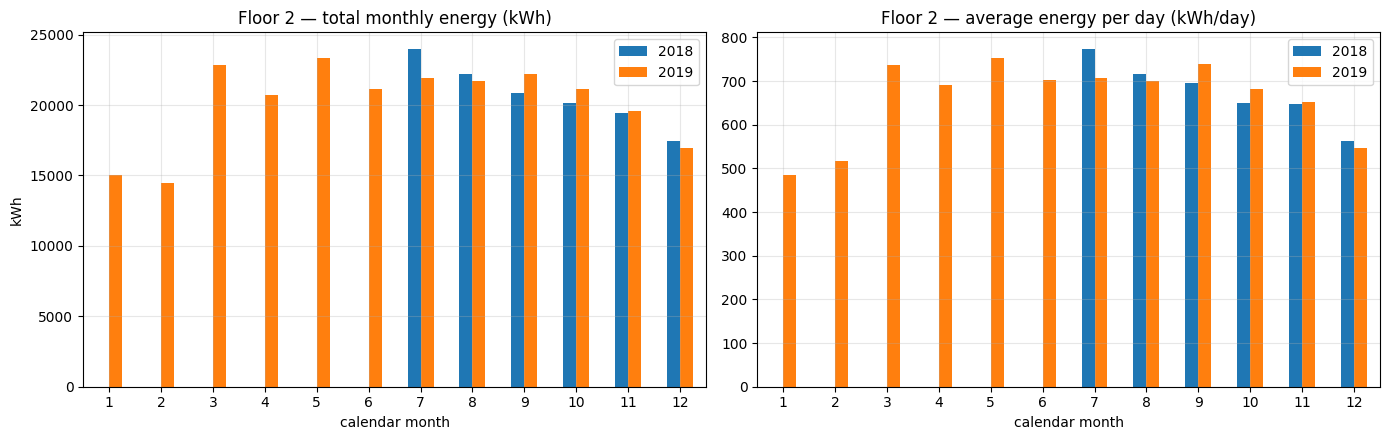

In [18]:
floor_piv = monthly['floor_kWh'].unstack('year')
floor_piv.columns = [str(c) for c in floor_piv.columns]
day_piv = monthly['kWh per day'].unstack('year')
day_piv.columns = [str(c) for c in day_piv.columns]
day_piv['delta %'] = (day_piv['2019'] - day_piv['2018']) / day_piv['2018'] * 100
display(day_piv.round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
floor_piv[['2018', '2019']].plot(kind='bar', ax=axes[0], color=['#1f77b4', '#ff7f0e'])
axes[0].set_title(f'{FLOOR} — total monthly energy (kWh)')
axes[0].set_xlabel('calendar month'); axes[0].set_ylabel('kWh'); axes[0].tick_params(axis='x', rotation=0)
day_piv[['2018', '2019']].plot(kind='bar', ax=axes[1], color=['#1f77b4', '#ff7f0e'])
axes[1].set_title(f'{FLOOR} — average energy per day (kWh/day)')
axes[1].set_xlabel('calendar month'); axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

In [19]:
common_months = monthly.loc[2018].index.intersection(monthly.loc[2019].index)
print('Months comparable across years:', list(common_months))

zone_2018 = monthly.loc[2018, zone_kwh_cols].div(monthly.loc[2018, 'days'], axis=0)
zone_2019 = monthly.loc[2019, zone_kwh_cols].div(monthly.loc[2019, 'days'], axis=0)
zone_yoy = pd.concat({'2018 kWh/day': zone_2018.loc[common_months].mean(),
                      '2019 kWh/day': zone_2019.loc[common_months].mean()}, axis=1)
zone_yoy['delta %'] = (zone_yoy['2019 kWh/day'] - zone_yoy['2018 kWh/day']) \
                      / zone_yoy['2018 kWh/day'] * 100
display(zone_yoy.round(1))

Months comparable across years: [7, 8, 9, 10, 11, 12]


,2018 kWh/day,2019 kWh/day,delta %
z1 kWh,299.4,299.4,-0.0
z2 kWh,271.4,288.0,6.1
z3 kWh,21.5,20.1,-6.5
z4 kWh,81.7,63.6,-22.2


## 8. Load profiles — *when* the floor uses energy

Four complementary views:

1. **Hour of day** — mean kW per hour, one line per year. This is also what justifies the
   08:00–17:00 occupancy proxy: the ramp is sharp and in the same place in both years.
2. **Hour × month heatmaps** — seasonal shifts in cooling and in working hours.
3. **Day of week** — the weekend drop.
4. **Occupied vs after-hours vs weekend** — as mean demand and as a share of total energy.
   This is the headline number for the after-hours question.

,2018,2019
hour,,
0,7.40,6.97
1,7.30,6.82
2,7.28,6.71
3,7.26,6.67
4,7.19,6.64
5,7.17,6.29
6,9.49,8.28
7,25.33,18.69
8,59.48,58.86


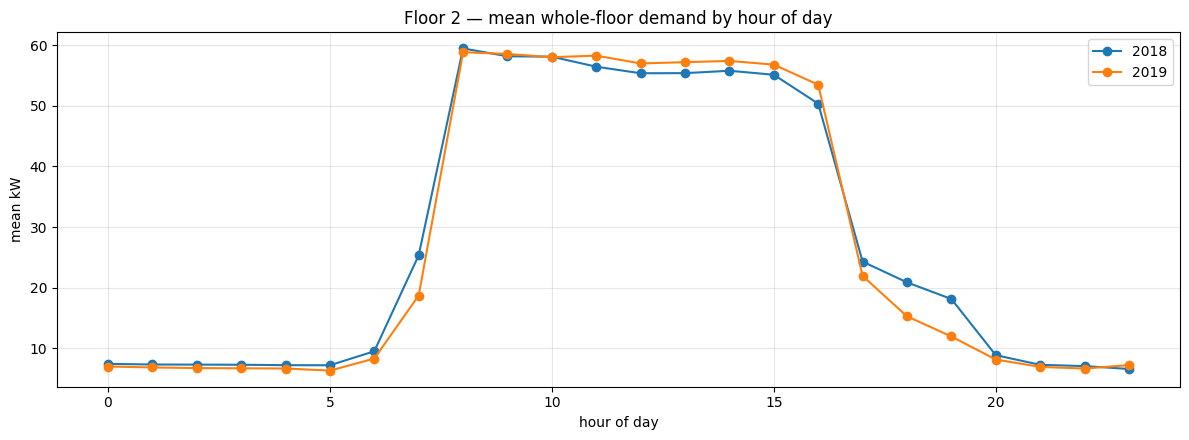

In [20]:
hourly = df_all.pivot_table(index='hour', columns='year', values='floor_total_kW', aggfunc='mean')
hourly.columns = [str(c) for c in hourly.columns]
display(hourly.round(2))
ax = hourly.plot(marker='o', figsize=(12, 4.5))
ax.set_title(f'{FLOOR} — mean whole-floor demand by hour of day')
ax.set_xlabel('hour of day'); ax.set_ylabel('mean kW')
plt.tight_layout(); plt.show()

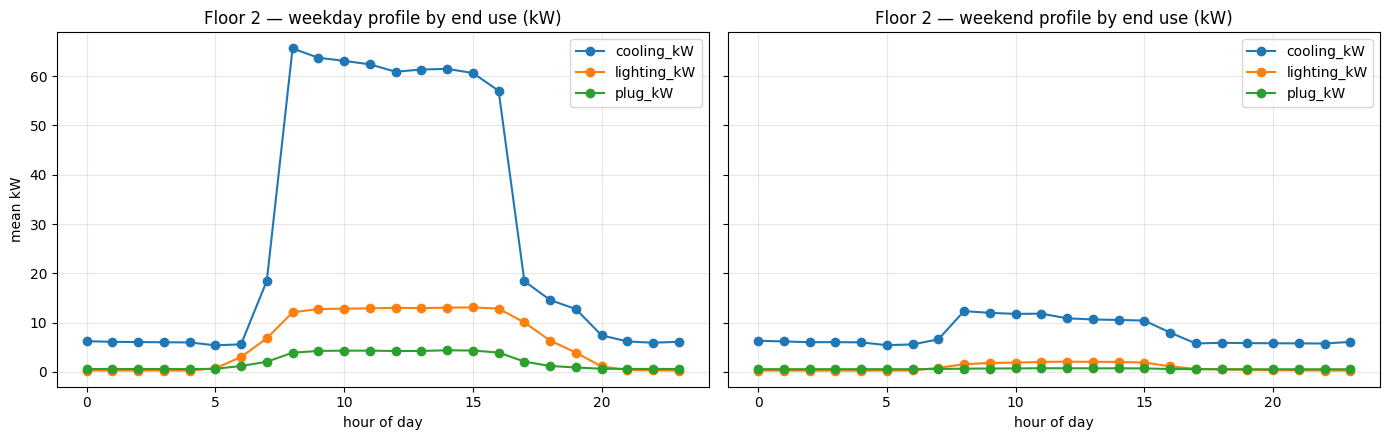

weekday                        weekend                    
     cooling_kW lighting_kW plug_kW cooling_kW lighting_kW plug_kW
hour                                                              
0          6.24        0.29    0.60       6.33        0.28    0.56
1          6.11        0.29    0.60       6.19        0.27    0.56
2          6.06        0.29    0.60       6.04        0.27    0.56
3          6.02        0.28    0.59       6.05        0.27    0.56
4          5.99        0.29    0.57       6.01        0.27    0.56
5          5.40        0.73    0.64       5.43        0.28    0.56
6          5.60        3.03    1.21       5.58        0.29    0.56
7         18.49        6.82    2.07       6.60        0.84    0.61
8         65.63       12.09    3.90      12.34        1.56    0.66
9         63.75       12.76    4.26      11.99        1.83    0.70
10        63.11       12.85    4.32      11.77        1.88    0.72
11        62.41       12.90    4.32      11.82        2.04    0.75
12        60.91       13.02    4.25      10.89        2.09    0.74
13        61.35       12.94    4.26      10.65        2.05    0.73
14        61.49       13.06    4.39      10.55        2.03    0.74
15        60.64       13.09    4.35      10.42        1.92    0.72
16        57.05       12.85    3.93       7.99        1.12    0.60
17        18.42       10.03    2.10       5.78        0.63    0.55
18        14.59        6.37    1.21       5.91        0.51    0.55
19        12.75        3.92    0.90       5.85        0.39    0.55
20         7.42        1.12    0.65       5.82        0.34    0.54
21         6.18        0.39    0.62       5.79        0.32    0.54
22         5.93        0.31    0.61       5.77        0.29    0.54
23         6.12        0.29    0.61       6.10        0.29    0.54

In [21]:
# End-use profile on weekdays only — shows the AC baseload that never switches off
wk = df_all[~df_all['is_weekend'] & ~df_all['is_holiday']]
prof = wk.pivot_table(index='hour', values=['cooling_kW', 'lighting_kW', 'plug_kW'], aggfunc='mean')
we = df_all[df_all['is_weekend']]
prof_we = we.pivot_table(index='hour', values=['cooling_kW', 'lighting_kW', 'plug_kW'], aggfunc='mean')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
prof.plot(ax=axes[0], marker='o'); axes[0].set_title(f'{FLOOR} — weekday profile by end use (kW)')
prof_we.plot(ax=axes[1], marker='o'); axes[1].set_title(f'{FLOOR} — weekend profile by end use (kW)')
for a in axes: a.set_xlabel('hour of day'); a.set_ylabel('mean kW')
plt.tight_layout(); plt.show()
display(pd.concat({'weekday': prof, 'weekend': prof_we}, axis=1).round(2))

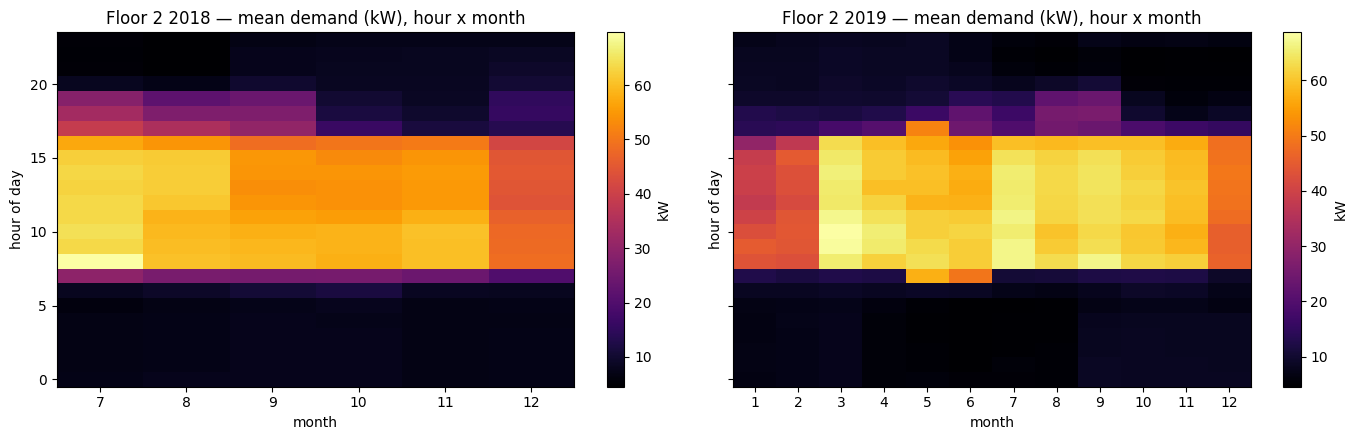

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (label, d) in zip(axes, [('2018', df18), ('2019', df19)]):
    piv = d.pivot_table(index='hour', columns='month', values='floor_total_kW', aggfunc='mean')
    im = ax.imshow(piv.values, cmap='inferno', origin='lower', aspect='auto')
    ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels(piv.columns)
    ax.set_xlabel('month'); ax.set_ylabel('hour of day')
    ax.set_title(f'{FLOOR} {label} — mean demand (kW), hour x month')
    ax.grid(False)
    fig.colorbar(im, ax=ax, label='kW')
plt.tight_layout(); plt.show()

,2018,2019
day_name,,
Monday,32.52,32.43
Tuesday,36.42,34.17
Wednesday,36.32,36.13
Thursday,36.86,35.79
Friday,35.72,35.82
Saturday,12.57,9.44
Sunday,7.18,8.77


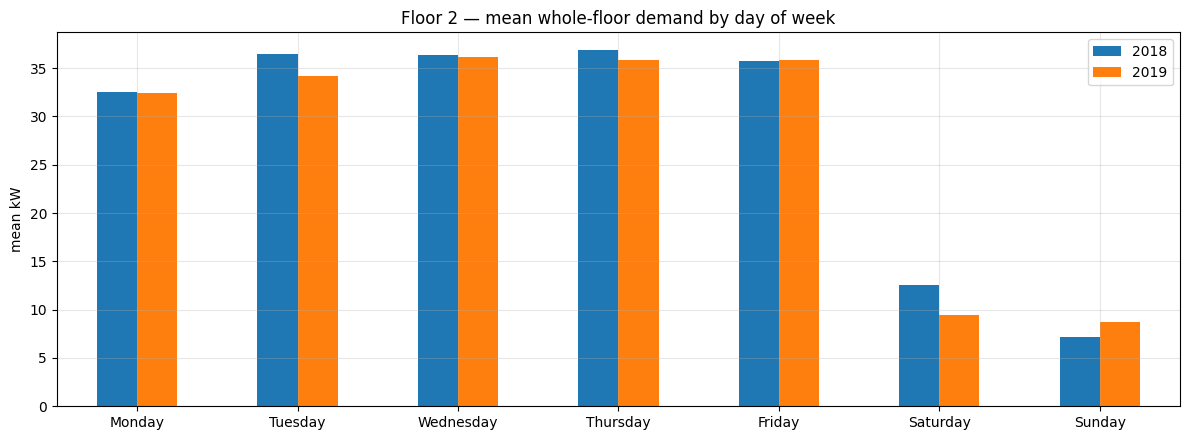

In [23]:
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow = (df_all.pivot_table(index='day_name', columns='year', values='floor_total_kW', aggfunc='mean')
       .reindex(dow_order))
dow.columns = [str(c) for c in dow.columns]
display(dow.round(2))
ax = dow.plot(kind='bar', figsize=(12, 4.5))
ax.set_title(f'{FLOOR} — mean whole-floor demand by day of week')
ax.set_xlabel(''); ax.set_ylabel('mean kW'); ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

In [23]:
df_all['period'] = np.select(
    [df_all['is_occupied'], df_all['is_weekend'] | df_all['is_holiday']],
    ['Weekday 08-17 (occupied)', 'Weekend / holiday'],
    default='Weekday off-hours')
period_order = ['Weekday 08-17 (occupied)', 'Weekday off-hours', 'Weekend / holiday']

period_kW = (df_all.pivot_table(index='period', columns='year',
                                values='floor_total_kW', aggfunc='mean').reindex(period_order))
period_kWh = (df_all.pivot_table(index='period', columns='year',
                                 values='floor_kWh', aggfunc='sum').reindex(period_order))
period_share = period_kWh / period_kWh.sum() * 100

out = pd.concat({'mean demand (kW)': period_kW.round(1),
                 'energy (kWh)': period_kWh.round(0),
                 'share of energy (%)': period_share.round(1)}, axis=1)
display(out)
print('Share of energy used OUTSIDE occupied hours:')
print((100 - period_share.loc['Weekday 08-17 (occupied)']).round(1))

mean demand (kW)       energy (kWh)           share of energy (%)      
year                                 2018  2019         2018      2019                2018  2019
period                                                                                          
Weekday 08-17 (occupied)             77.3  79.6      85204.0  174802.0                68.7  72.5
Weekday off-hours                    13.5  11.2      24947.0   40828.0                20.1  16.9
Weekend / holiday                     9.5   8.7      13871.0   25344.0                11.2  10.5

Share of energy used OUTSIDE occupied hours:
year
2018    31.3
2019    27.5
Name: Weekday 08-17 (occupied), dtype: float64


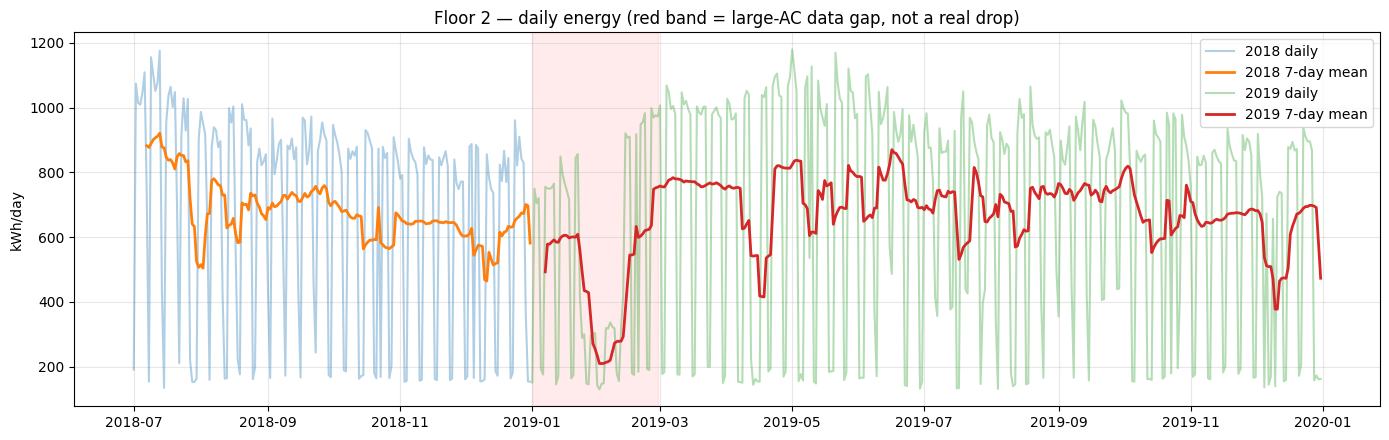

In [24]:
daily_kwh = {}
for label, d in [('2018', df18), ('2019', df19)]:
    s = d.groupby('date')['floor_kWh'].sum()
    s.index = pd.to_datetime(s.index)
    daily_kwh[label] = s

fig, ax = plt.subplots(figsize=(14, 4.5))
for label, s in daily_kwh.items():
    ax.plot(s.index, s.values, alpha=0.35, label=f'{label} daily')
    ax.plot(s.index, s.rolling(7, min_periods=7).mean().values, lw=2, label=f'{label} 7-day mean')
ax.axvspan(pd.Timestamp('2019-01-01'), pd.Timestamp('2019-02-28'), color='red', alpha=0.08)
ax.set_title(f'{FLOOR} — daily energy (red band = large-AC data gap, not a real drop)')
ax.set_ylabel('kWh/day'); ax.legend()
plt.tight_layout(); plt.show()

## 9. Peak, base load and load factor

Standard energy-audit demand metrics per zone and for the whole floor. **Base load (p5)** is the
one to watch on Floor 2: a high 5th-percentile means the floor never really switches off.

In [25]:
def demand_metrics(s):
    return pd.Series({
        'Peak 1-min (kW)': s.max(),
        'Peak 15-min avg (kW)': s.rolling(15, min_periods=15).mean().max(),
        'Average demand (kW)': s.mean(),
        'Base load p5 (kW)': s.quantile(0.05),
        'Load factor': s.mean() / s.max(),
        'Std dev (kW)': s.std(),
    })

metric_cols = [f'{z}_total_kW' for z in zone_ids] + ['floor_total_kW']
tbl18 = pd.concat({c: demand_metrics(df18[c]) for c in metric_cols}, axis=1)
tbl19 = pd.concat({c: demand_metrics(df19[c]) for c in metric_cols}, axis=1)
display(pd.concat({'2018': tbl18.T, '2019': tbl19.T}, axis=1).round(2))

base_vs_peak = pd.DataFrame({
    'base load p5 (kW)': [df19[c].quantile(0.05) for c in metric_cols],
    'peak (kW)': [df19[c].max() for c in metric_cols],
}, index=metric_cols)
base_vs_peak['base as % of peak'] = base_vs_peak['base load p5 (kW)'] / base_vs_peak['peak (kW)'] * 100
display(base_vs_peak.round(1))

2018                                                                                                2019                       \
               Peak 1-min (kW) Peak 15-min avg (kW) Average demand (kW) Base load p5 (kW) Load factor Std dev (kW) Peak 1-min (kW) Peak 15-min avg (kW)   
z1_total_kW              71.38                53.30               12.49              0.15        0.17        17.95           75.90                55.72   
z2_total_kW              74.23                43.31               11.33              3.29        0.15         8.75           59.50                47.54   
z3_total_kW              15.18                 4.00                0.90              0.34        0.06         0.57           14.02                 3.10   
z4_total_kW              54.32                14.25                3.41              0.00        0.06         5.23           55.33                13.15   
floor_total_kW          146.81               106.23               28.13              4.02        0.19        31.24          130.38               115.90   

                                                                               
               Average demand (kW) Base load p5 (kW) Load factor Std dev (kW)  
z1_total_kW                  11.80              0.15        0.16        17.86  
z2_total_kW                  12.27              3.38        0.21        11.71  
z3_total_kW                   0.83              0.30        0.06         0.43  
z4_total_kW                   2.63              0.00        0.05         4.51  
floor_total_kW               27.53              4.20        0.21        33.35

,base load p5 (kW),peak (kW),base as % of peak
z1_total_kW,0.2,75.9,0.2
z2_total_kW,3.4,59.5,5.7
z3_total_kW,0.3,14.0,2.1
z4_total_kW,0.0,55.3,0.0
floor_total_kW,4.2,130.4,3.2


## 10. Indoor environment (temperature, humidity, illuminance)

**Deliberately defensive.** The sensors are missing a third to a half of all rows, so:

1. **Measure coverage first** — `%` of valid readings per year × month × sensor.
2. **Mask unreliable cells** — any year/month below 50 % coverage becomes `NaN` before plotting.
3. Only then report means.

The illuminance result on this floor is worth noting: lux is effectively zero whenever the lights
are off, even at midday, so the sensors are reading the lamps rather than daylight. Any
"daylight dimming" analysis built on these columns would be circular.

z1     z2    z3     z4
year month                           
2018 7       97.0   96.0  98.0    0.0
     8       96.0   96.0  96.0    0.0
     9       37.0   37.0  37.0    0.0
     10       0.0    0.0   0.0    0.0
     11       0.0    0.0   0.0    0.0
     12       0.0    0.0   0.0    0.0
2019 1        0.0    0.0   0.0    0.0
     2        0.0    0.0   0.0    0.0
     3       81.0   82.0  83.0   67.0
     4      100.0   99.0  99.0   99.0
     5       99.0   99.0  98.0  100.0
     6       99.0   99.0  98.0   99.0
     7       66.0   98.0  97.0   99.0
     8      100.0  100.0  98.0   99.0
     9       99.0   98.0  97.0   99.0
     10      99.0   99.0  98.0  100.0
     11      99.0   99.0  95.0   99.0
     12      99.0   99.0  99.0   99.0

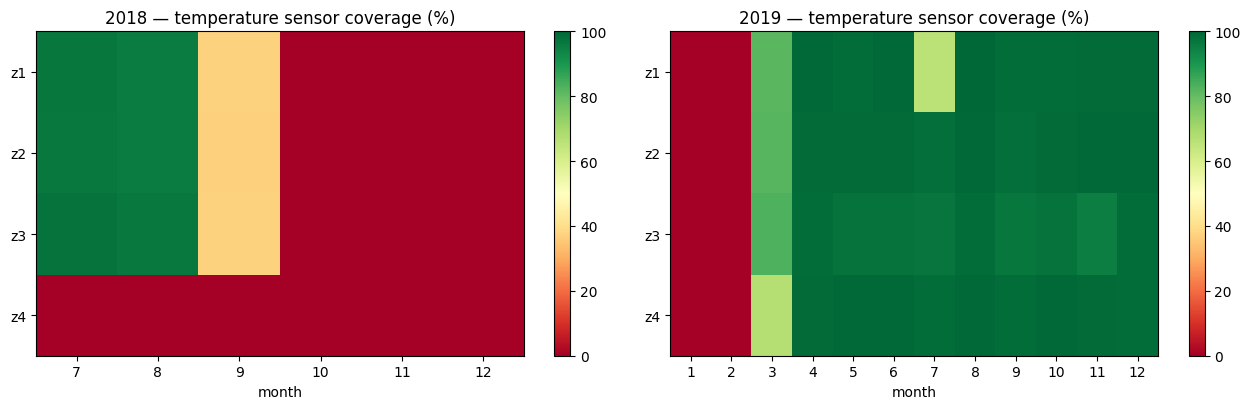

In [26]:
notna_mask = df_all[temp_cols].notna().astype(int)
coverage = notna_mask.groupby([df_all['year'], df_all['month']]).mean().mul(100)
coverage.columns = [c.split('_')[0] for c in coverage.columns]
display(coverage.round(0))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, yr in zip(axes, [2018, 2019]):
    sub = coverage.loc[yr]
    im = ax.imshow(sub.T.values, cmap='RdYlGn', vmin=0, vmax=100, aspect='auto')
    ax.set_xticks(range(len(sub.index))); ax.set_xticklabels(sub.index)
    ax.set_yticks(range(len(sub.columns))); ax.set_yticklabels(sub.columns)
    ax.set_title(f'{yr} — temperature sensor coverage (%)'); ax.set_xlabel('month')
    ax.grid(False); fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

In [27]:
MIN_COVERAGE = 50

def monthly_env_means(cols):
    means = df_all.groupby(['year', 'month'])[cols].mean()
    cov = (df_all[cols].notna().astype(int)
           .groupby([df_all['year'], df_all['month']]).mean().mul(100))
    means = means.where(cov >= MIN_COVERAGE)
    means.columns = [c.split('_')[0] for c in means.columns]
    return means

temp_m = monthly_env_means(temp_cols)
rh_m   = monthly_env_means(rh_cols)
lux_m  = monthly_env_means(lux_cols)
display(temp_m.round(1))

z1    z2    z3    z4
year month                        
2018 7      26.3  26.7  28.7   NaN
     8      26.0  28.1  29.2   NaN
     9       NaN   NaN   NaN   NaN
     10      NaN   NaN   NaN   NaN
     11      NaN   NaN   NaN   NaN
     12      NaN   NaN   NaN   NaN
2019 1       NaN   NaN   NaN   NaN
     2       NaN   NaN   NaN   NaN
     3      24.4  24.8  27.7  23.4
     4      26.0  26.4  29.1  25.1
     5      24.9  25.7  28.2  23.5
     6      24.0  25.3  27.3  23.7
     7      24.1  25.3  27.1  23.7
     8      23.7  24.7  26.8  23.2
     9      22.8  24.1  26.1  22.8
     10     24.8  25.0  27.4  23.6
     11     24.4  24.1  26.8  23.0
     12     24.4  24.2  26.3  23.5

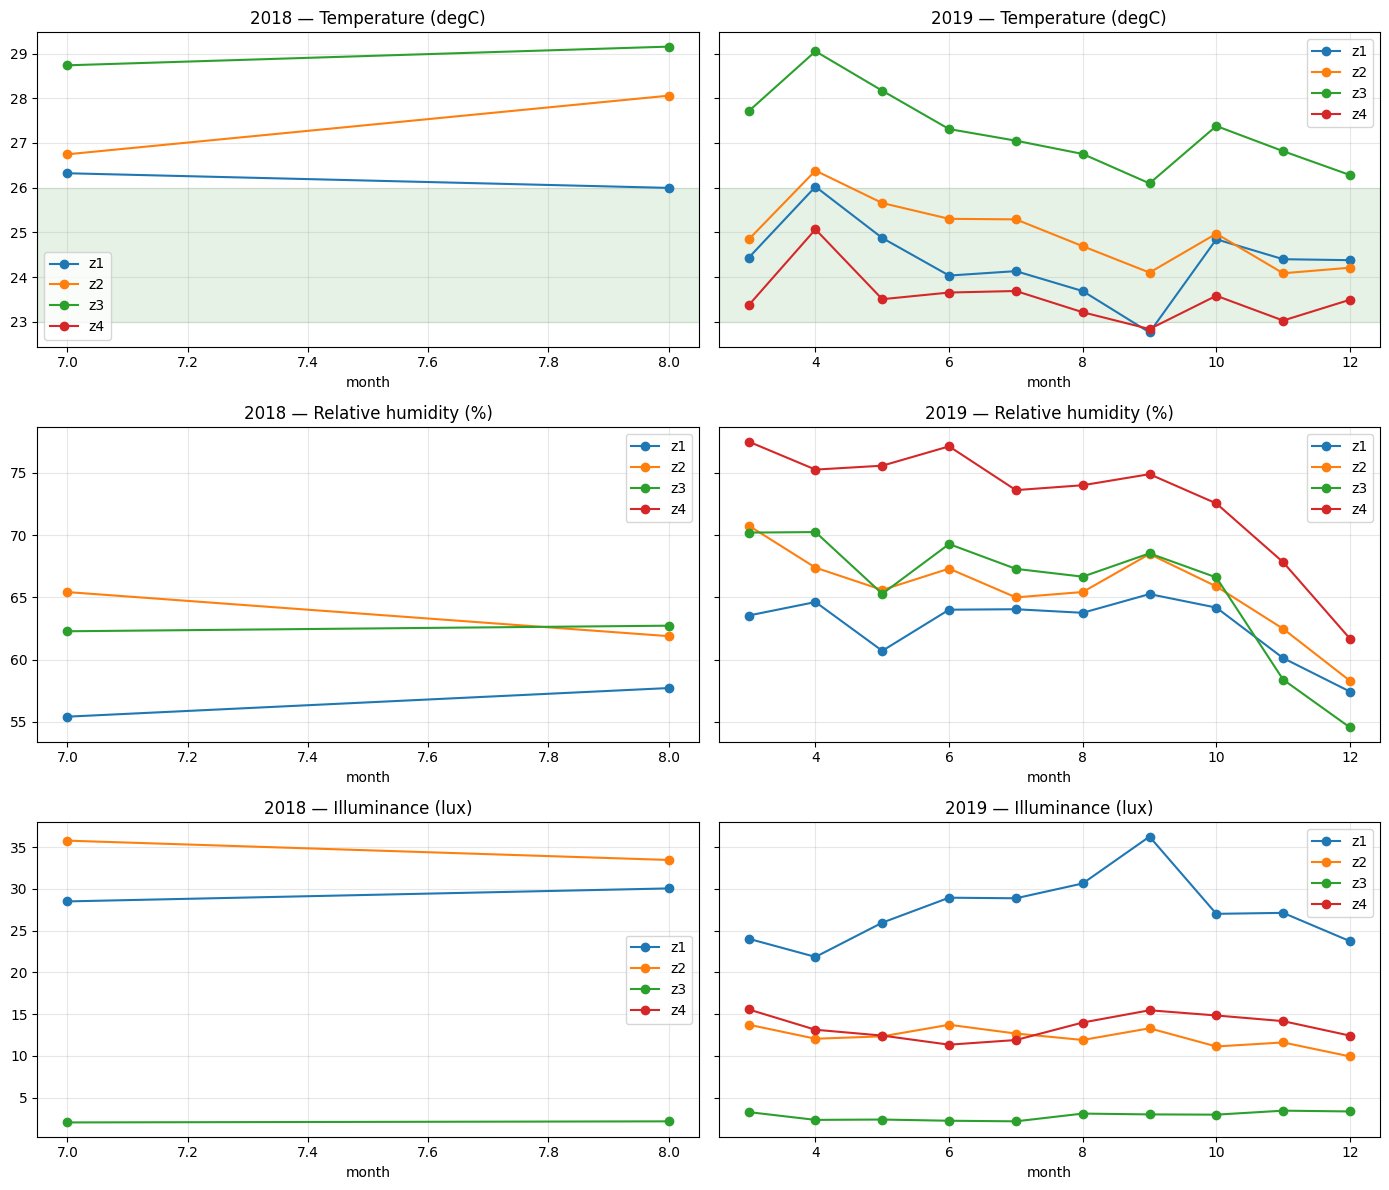

In [28]:
metrics = [('Temperature (degC)', temp_m, 2),
           ('Relative humidity (%)', rh_m, 1),
           ('Illuminance (lux)', lux_m, 0)]

fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharey='row')
for row, (title, tbl, dec) in enumerate(metrics):
    for col, yr in enumerate([2018, 2019]):
        ax = axes[row, col]
        if yr in tbl.index.get_level_values(0):
            tbl.loc[yr].plot(ax=ax, marker='o')
        ax.set_title(f'{yr} — {title}'); ax.set_xlabel('month')
        if row == 0:
            ax.axhspan(23, 26, color='green', alpha=0.10)
plt.tight_layout(); plt.show()

In [29]:
def env_summary(d, label):
    temp = d[temp_cols].to_numpy().ravel(); temp = temp[~np.isnan(temp)]
    rh = d[rh_cols].to_numpy().ravel();     rh = rh[~np.isnan(rh)]
    lux = d[lux_cols].to_numpy().ravel();   lux = lux[~np.isnan(lux)]
    return pd.Series({
        'valid sensor readings': int(temp.size),
        'temp mean (degC)': np.mean(temp) if temp.size else np.nan,
        'temp min (degC)': np.min(temp) if temp.size else np.nan,
        'temp max (degC)': np.max(temp) if temp.size else np.nan,
        'RH mean (%)': np.mean(rh) if rh.size else np.nan,
        'lux mean': np.mean(lux) if lux.size else np.nan,
        'lux max': np.max(lux) if lux.size else np.nan,
    }, name=label)

display(pd.concat([env_summary(df18, '2018'), env_summary(df19, '2019')], axis=1).round(1))

# Is lux measuring daylight or the lamps?  Midday readings with the lights off vs on.
midday = df_all[df_all['hour'].between(9, 15)]
lux_check = pd.DataFrame({
    'mean lux, lights OFF (<0.05 kW)': [midday.loc[midday[f'{z}_Light(kW)'] < 0.05, f'{z}_S1(lux)'].mean()
                                        for z in zone_ids],
    'mean lux, lights ON (>0.5 kW)': [midday.loc[midday[f'{z}_Light(kW)'] > 0.5, f'{z}_S1(lux)'].mean()
                                      for z in zone_ids],
    'corr(light kW, lux)': [df_all[f'{z}_Light(kW)'].corr(df_all[f'{z}_S1(lux)']) for z in zone_ids],
}, index=zone_ids)
display(lux_check.round(2))

,2018,2019
valid sensor readings,306153.0,1688075.0
temp mean (degC),27.5,25.0
temp min (degC),21.3,16.1
temp max (degC),30.9,32.1
RH mean (%),60.6,66.7
lux mean,21.9,13.9
lux max,138.0,92.0


,"mean lux, lights OFF (<0.05 kW)","mean lux, lights ON (>0.5 kW)","corr(light kW, lux)"
z1,3.53,72.83,0.95
z2,0.22,55.67,0.81
z3,4.53,5.83,0.48
z4,0.81,41.02,0.97


## 11. Correlations

Pearson correlations answer two questions: does cooling load track indoor temperature, and did
the relationships change between years?

**Interpret with care.** A *negative* correlation between cooling and indoor temperature does not
mean cooling warms the room — it means the AC is doing its job: more cooling produces a lower
temperature. Indoor temperature is an *outcome* of cooling, not a driver of it. Without outdoor
weather data (not in CU-BEMS; it can be added from an external source) these correlations
describe association only.

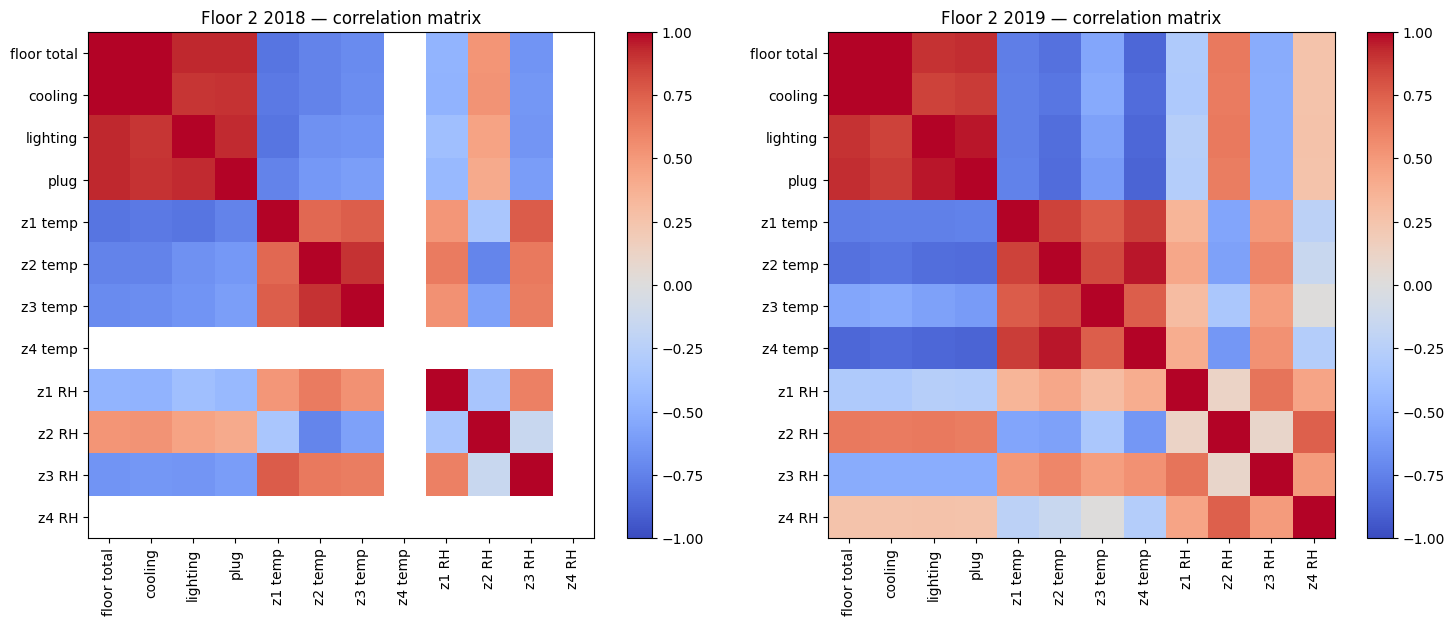

In [30]:
corr_cols = ['floor_total_kW', 'cooling_kW', 'lighting_kW', 'plug_kW'] + temp_cols + rh_cols

def short_label(c):
    if c.endswith('_S1(degC)'):
        return c.split('_')[0] + ' temp'
    if c.endswith('_S1(RH%)'):
        return c.split('_')[0] + ' RH'
    return c.replace('_total_kW', ' total').replace('_kW', '')

short = {c: short_label(c) for c in corr_cols}

def corr_of(d):
    return d[corr_cols].corr().rename(index=short, columns=short)

corr18, corr19 = corr_of(df18), corr_of(df19)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (label, m) in zip(axes, [('2018', corr18), ('2019', corr19)]):
    im = ax.imshow(m.values, cmap='coolwarm', vmin=-1, vmax=1)
    ax.set_xticks(range(len(m))); ax.set_xticklabels(m.columns, rotation=90)
    ax.set_yticks(range(len(m))); ax.set_yticklabels(m.index)
    ax.set_title(f'{FLOOR} {label} — correlation matrix'); ax.grid(False)
    fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

In [31]:
key = pd.DataFrame({'2018': corr18.loc['floor total'], '2019': corr19.loc['floor total']})
key = key.drop(index='floor total').sort_values('2019', key=lambda s: s.abs(), ascending=False)
display(key.round(2))

ac_temp = pd.DataFrame({
    '2018 corr(cooling, zone temp)': [corr18.loc['cooling', short[c]] for c in temp_cols],
    '2019 corr(cooling, zone temp)': [corr19.loc['cooling', short[c]] for c in temp_cols],
}, index=[c.split('_')[0] for c in temp_cols])
display(ac_temp.round(2))

,2018,2019
cooling,0.99,0.99
plug,0.93,0.92
lighting,0.93,0.90
z4 temp,NaN,-0.87
z2 temp,-0.74,-0.82
z1 temp,-0.81,-0.76
z2 RH,0.52,0.65
z3 temp,-0.70,-0.55
z3 RH,-0.65,-0.52
z1 RH,-0.47,-0.30


,"2018 corr(cooling, zone temp)","2019 corr(cooling, zone temp)"
z1,-0.79,-0.75
z2,-0.74,-0.80
z3,-0.69,-0.53
z4,NaN,-0.85


## 12. Anomaly detection on daily energy

Two statistical tests, because one alone misleads on this dataset:

1. **Tukey IQR fences computed separately for weekdays and weekends**, since daily energy is
   strongly bimodal. `low = Q1 − 1.5·IQR`, `high = Q3 + 1.5·IQR`.
2. **Z-score within each day of week**, which catches a Tuesday that behaves unlike other Tuesdays.

Thai public holidays are labelled so they are not mistaken for faults — a flagged low day that is
a holiday is expected behaviour, not an anomaly.

In [32]:
daily = (df_all.groupby(['year', 'date'])
         .agg(kWh=('floor_kWh', 'sum'),
              avg_kW=('floor_total_kW', 'mean'),
              reported_minutes=('floor_total_kW', 'count'))
         .reset_index())
daily['day_of_week'] = pd.to_datetime(daily['date']).dt.dayofweek
daily['day_name'] = pd.to_datetime(daily['date']).dt.day_name()
daily['is_weekend'] = daily['day_of_week'] >= 5
daily['is_holiday'] = daily['date'].isin(THAI_HOLIDAYS)

# Tukey fences per (year, day-type), merged back on - no groupby.apply needed
fences = (daily.groupby(['year', 'is_weekend'])['kWh']
          .agg(q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75)))
fences['low_fence'] = fences['q1'] - 1.5 * (fences['q3'] - fences['q1'])
fences['high_fence'] = fences['q3'] + 1.5 * (fences['q3'] - fences['q1'])
daily = daily.merge(fences[['low_fence', 'high_fence']],
                    left_on=['year', 'is_weekend'], right_index=True)
daily['flag'] = np.select([daily['kWh'] > daily['high_fence'],
                           daily['kWh'] < daily['low_fence']], ['HIGH', 'LOW'], default='')
dow_stats = daily.groupby(['year', 'day_name'])['kWh'].agg(['mean', 'std']).rename(
    columns={'mean': 'dow_mean', 'std': 'dow_std'})
daily = daily.merge(dow_stats, left_on=['year', 'day_name'], right_index=True)
daily['z'] = (daily['kWh'] - daily['dow_mean']) / daily['dow_std']
daily['flag_z'] = np.where(daily['z'].abs() > 3, 'Z>3', '')

print('Days flagged by Tukey fences:', int((daily['flag'] != '').sum()),
      '| of which holidays:', int(((daily['flag'] != '') & daily['is_holiday']).sum()))
print('Days flagged by z-score:', int((daily['flag_z'] != '').sum()))
display(daily[daily['flag'] != ''][['year', 'date', 'day_name', 'kWh', 'flag',
                                    'is_holiday', 'reported_minutes']].head(25))

Days flagged by Tukey fences: 79 | of which holidays: 25
Days flagged by z-score: 10


,year,date,day_name,kWh,flag,is_holiday,reported_minutes
5,2018,2018-07-06,Friday,1109.324833,HIGH,False,1440
6,2018,2018-07-07,Saturday,733.191667,HIGH,False,1440
8,2018,2018-07-09,Monday,1155.815167,HIGH,False,1440
9,2018,2018-07-10,Tuesday,1101.362500,HIGH,False,1440
12,2018,2018-07-13,Friday,1175.687333,HIGH,False,1440
13,2018,2018-07-14,Saturday,435.337500,HIGH,False,1440
20,2018,2018-07-21,Saturday,693.148000,HIGH,False,1440
26,2018,2018-07-27,Friday,220.505500,LOW,True,1440
29,2018,2018-07-30,Monday,163.222333,LOW,True,1440
34,2018,2018-08-04,Saturday,631.880167,HIGH,False,1440


In [33]:
top10 = daily.nlargest(10, 'kWh')[['year', 'date', 'day_name', 'kWh', 'avg_kW', 'high_fence', 'flag', 'z']]
display(top10.round(1))

unusual = (daily.reindex(daily['z'].abs().sort_values(ascending=False).index).head(10)
           [['year', 'date', 'day_name', 'kWh', 'dow_mean', 'z', 'is_holiday']])
display(unusual.round(1))

# Weekdays running far below normal that are NOT holidays and NOT missing data
suspect_low = daily[(daily['flag'] == 'LOW') & ~daily['is_weekend'] & ~daily['is_holiday']
                    & (daily['reported_minutes'] > 1400)]
print('Low weekdays that are not public holidays and have full data:')
display(suspect_low[['year', 'date', 'day_name', 'kWh', 'low_fence']].round(1))

,year,date,day_name,kWh,avg_kW,high_fence,flag,z
304,2019,2019-05-01,Wednesday,1180.1,49.2,1202.8,,1.4
12,2018,2018-07-13,Friday,1175.7,49.0,1094.4,HIGH,1.9
324,2019,2019-05-21,Tuesday,1169.7,48.7,1202.8,,1.2
8,2018,2018-07-09,Monday,1155.8,48.2,1094.4,HIGH,1.2
313,2019,2019-05-10,Friday,1127.3,47.0,1202.8,,1.3
330,2019,2019-05-27,Monday,1120.9,46.7,1202.8,,1.1
305,2019,2019-05-02,Thursday,1117.9,46.6,1202.8,,1.2
5,2018,2018-07-06,Friday,1109.3,46.2,1094.4,HIGH,1.5
297,2019,2019-04-24,Wednesday,1105.3,46.1,1202.8,,1.1
339,2019,2019-06-05,Wednesday,1103.2,46.0,1202.8,,1.1


,year,date,day_name,kWh,dow_mean,z,is_holiday
157,2018,2018-12-05,Wednesday,165.5,870.6,-4.3,True
114,2018,2018-10-23,Tuesday,168.4,874.2,-4.2,True
26,2018,2018-07-27,Friday,220.5,850.0,-3.6,True
215,2019,2019-02-01,Friday,130.5,858.2,-3.5,False
522,2019,2019-12-05,Thursday,136.6,859.0,-3.4,True
214,2019,2019-01-31,Thursday,142.2,859.0,-3.4,False
381,2019,2019-07-17,Wednesday,134.3,867.2,-3.3,True
84,2018,2018-09-23,Sunday,243.7,172.3,3.3,False
479,2019,2019-10-23,Wednesday,179.6,867.2,-3.1,True
285,2019,2019-04-12,Friday,222.3,858.2,-3.1,False


Low weekdays that are not public holidays and have full data:


,year,date,day_name,kWh,low_fence
206,2019,2019-01-23,Wednesday,416.2,615.1
207,2019,2019-01-24,Thursday,288.7,615.1
208,2019,2019-01-25,Friday,300.5,615.1
211,2019,2019-01-28,Monday,297.4,615.1
212,2019,2019-01-29,Tuesday,302.7,615.1
213,2019,2019-01-30,Wednesday,303.8,615.1
214,2019,2019-01-31,Thursday,142.2,615.1
215,2019,2019-02-01,Friday,130.5,615.1
218,2019,2019-02-04,Monday,319.4,615.1
219,2019,2019-02-05,Tuesday,318.0,615.1


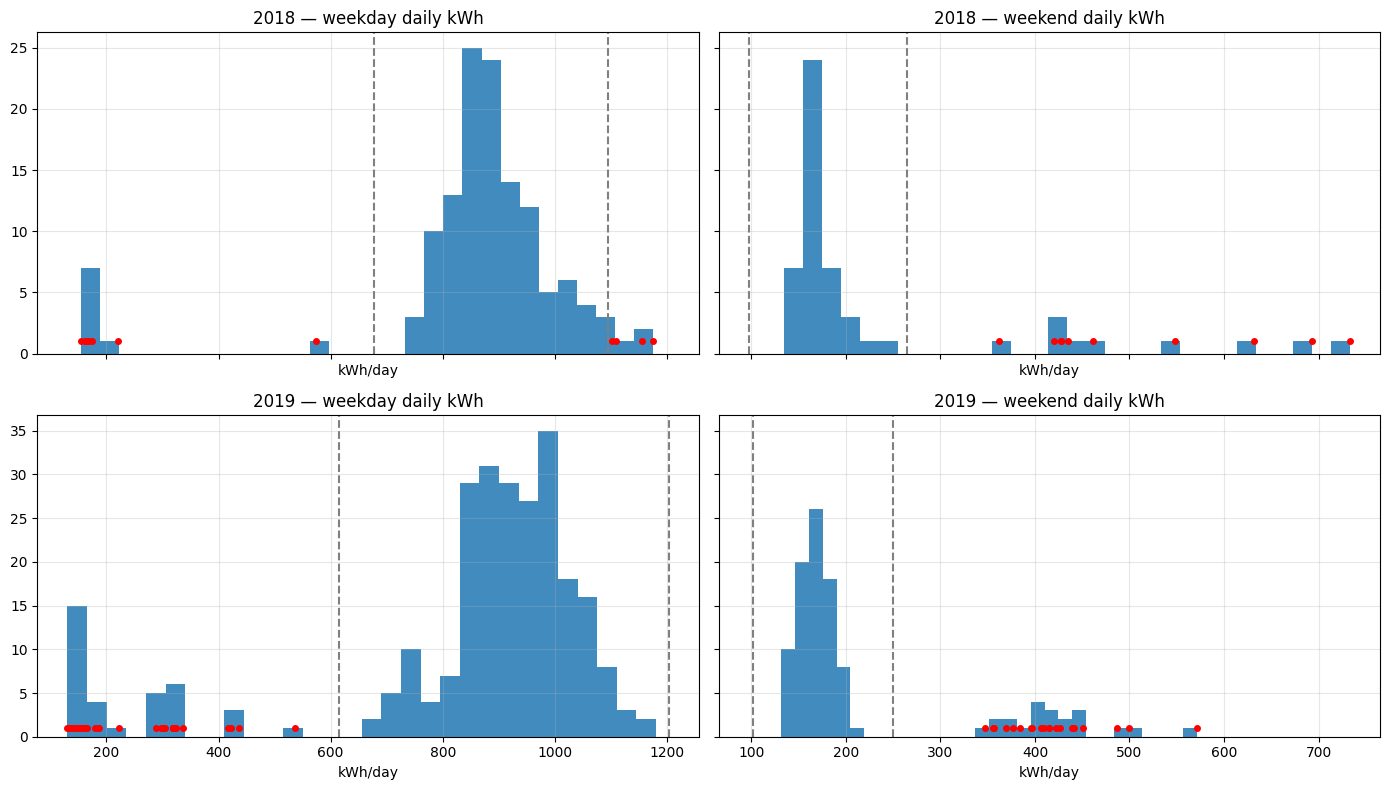

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex='col', sharey='row')
for r, yr in enumerate([2018, 2019]):
    for c, wknd in enumerate([False, True]):
        ax = axes[r, c]
        g = daily[(daily['year'] == yr) & (daily['is_weekend'] == wknd)]
        ax.hist(g['kWh'], bins=30, color='#1f77b4', alpha=0.85)
        ax.axvline(g['low_fence'].iloc[0], ls='--', color='grey')
        ax.axvline(g['high_fence'].iloc[0], ls='--', color='grey')
        flagged = g[g['flag'] != '']
        ax.plot(flagged['kWh'], np.full(len(flagged), 1), 'o', color='red', ms=4)
        ax.set_title(f'{yr} — {"weekend" if wknd else "weekday"} daily kWh')
        ax.set_xlabel('kWh/day')
plt.tight_layout(); plt.show()

## 13. Floor 2 in detail — AC units, after-hours runtime and the comfort band

This section is specific to Floor 2 and is where its two project questions come from. Floor 6 has
one AC unit per zone; Floor 2 has fourteen in Zone 2 alone, so the interesting behaviour is at
**unit level**, not zone level.

**13.1 Which units run when nobody is there?** For each unit, mean demand during occupied hours is
compared with mean demand at night (22:00–05:00). A ratio near 1 means the unit does not know the
difference between day and night.

**13.2 Duty rotation.** The small Zone 2 units turn out to operate in three groups of three that
swap over roughly twice in the 18 months — the signature of duty/standby rotation on a space that
is cooled continuously. This is *evidence to take to facilities*, not a fault: a server or
equipment room would look exactly like this. What is worth asking is why two groups run
simultaneously overnight rather than one.

**13.3 Comfort band.** Share of occupied minutes below 23 °C, within 23–26 °C and above 26 °C per
zone, plus "overcooling degree-hours" = Σ max(0, 23 − T) × hours, which turns "too cold" into a
single number that can be tracked after a setpoint change. Zone 3 is uncooled and acts as a
control. A comfort band must be cited from a standard (ASHRAE 55, or a Thai building standard,
which suits a Bangkok building better) — 23–26 °C is used here as a placeholder.

In [35]:
# 13.1 Occupied vs night demand, per unit (2019, excluding the Jan-Feb data gap)
d19 = df19[df19['Date'] >= '2019-03-01']
live_power = [c for c in power_cols if c not in DEAD_UNITS]

unit_tbl = pd.DataFrame({
    'occupied mean (kW)': d19.loc[d19['is_occupied'], live_power].mean(),
    'night mean (kW)': d19.loc[d19['is_night'], live_power].mean(),
    'weekend day mean (kW)': d19.loc[d19['is_weekend'] & d19['hour'].between(8, 16), live_power].mean(),
})
unit_tbl['night as % of occupied'] = unit_tbl['night mean (kW)'] / unit_tbl['occupied mean (kW)'] * 100
unit_tbl['2019 kWh'] = (df19[live_power] / 60).sum()
unit_tbl['% of 2019 kWh outside occupied hrs'] = (
    (df19.loc[~df19['is_occupied'], live_power] / 60).sum() / (df19[live_power] / 60).sum() * 100)
display(unit_tbl.sort_values('night as % of occupied', ascending=False).round(2))

,occupied mean (kW),night mean (kW),weekend day mean (kW),night as % of occupied,2019 kWh,% of 2019 kWh outside occupied hrs
z2_AC8(kW),0.15,0.48,0.22,321.54,2888.35,88.32
z2_AC10(kW),0.17,0.54,0.26,310.43,3287.73,87.99
z2_AC6(kW),0.35,0.75,0.44,214.80,4821.82,84.55
z2_AC7(kW),0.61,0.60,0.76,99.40,5770.04,75.47
z4_Plug(kW),0.03,0.03,0.03,97.95,236.12,74.53
z2_AC9(kW),0.68,0.66,0.84,97.49,6393.05,75.12
z2_AC5(kW),0.94,0.90,1.10,96.38,8609.96,74.78
z3_Plug(kW),0.41,0.25,0.28,60.22,2650.56,66.43
z2_AC3(kW),0.63,0.29,0.57,45.41,3534.76,66.13
z2_AC2(kW),0.90,0.41,0.85,45.40,5333.80,66.61


,z2_AC2(kW),z2_AC3(kW),z2_AC4(kW),z2_AC5(kW),z2_AC6(kW),z2_AC7(kW),z2_AC8(kW),z2_AC9(kW),z2_AC10(kW),z2_AC13(kW),z2_AC14(kW)
Date,,,,,,,,,,,
2018-07,0.10,0.03,0.04,1.26,0.61,0.84,0.38,0.93,0.44,0.01,0.0
2018-08,0.11,0.04,0.04,1.27,0.77,0.83,0.53,0.93,0.61,0.00,0.0
2018-09,0.80,0.59,0.66,0.43,1.08,0.28,0.77,0.32,0.89,0.00,0.0
2018-10,0.96,0.73,0.79,0.26,1.14,0.18,0.82,0.19,0.93,0.00,0.0
2018-11,0.93,0.69,0.77,0.30,1.06,0.20,0.74,0.22,0.84,0.00,0.0
2018-12,0.94,0.69,0.77,0.30,1.05,0.20,0.73,0.22,0.82,0.01,0.0
2019-01,0.92,0.68,0.75,0.31,1.03,0.21,0.71,0.23,0.80,0.09,0.0
2019-02,0.92,0.69,0.76,0.32,1.21,0.22,0.88,0.24,0.98,0.00,0.0
2019-03,0.91,0.69,0.75,0.33,1.16,0.23,0.84,0.25,0.94,0.01,0.0


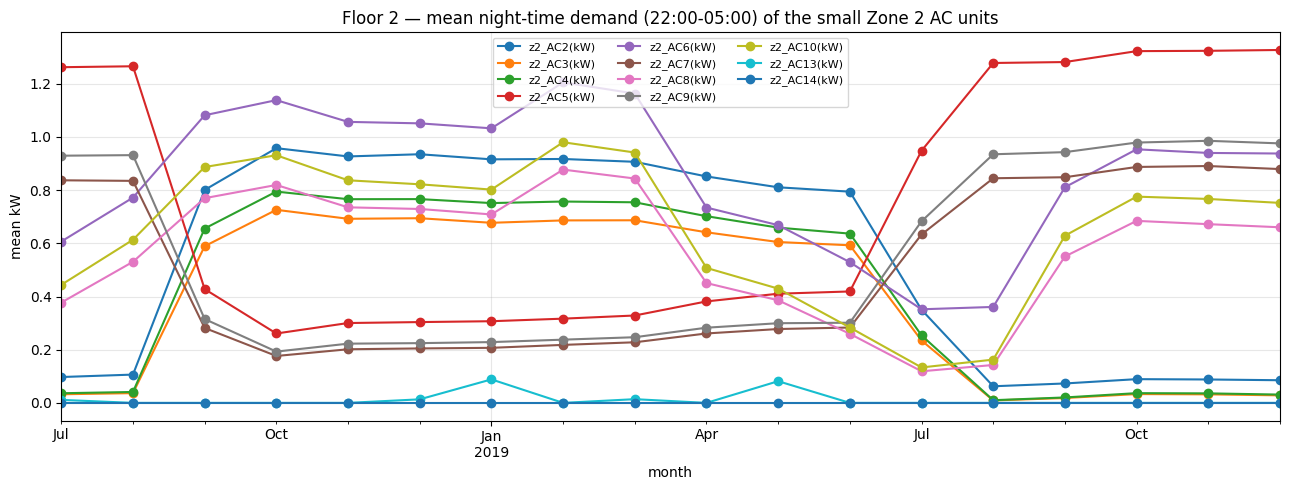

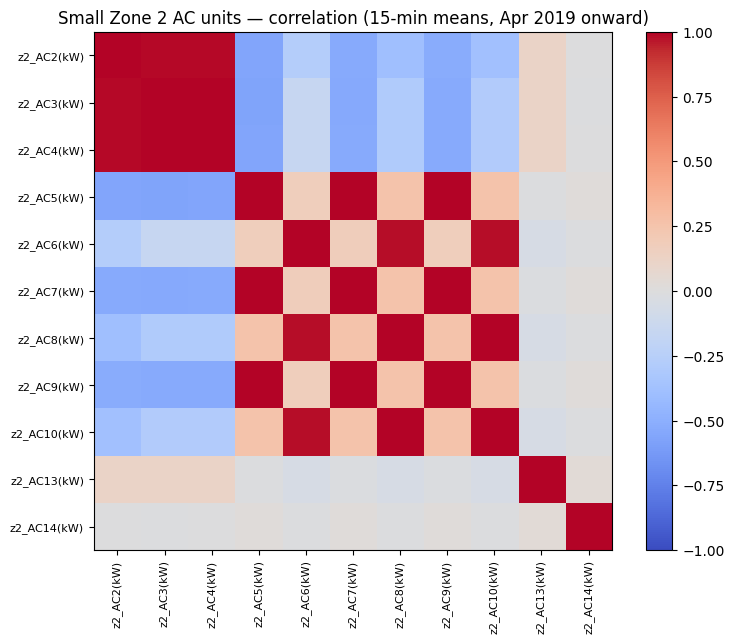

In [36]:
# 13.2 Duty rotation of the small Zone 2 units
small = [c for c in ac_cols if c.startswith('z2_AC') and c not in ['z2_AC1(kW)'] + DEAD_UNITS]
night_monthly = (df_all[df_all['is_night']]
                 .groupby(df_all.loc[df_all['is_night'], 'Date'].dt.to_period('M'))[small].mean())
display(night_monthly.round(2))

ax = night_monthly.plot(figsize=(13, 5), marker='o')
ax.set_title(f'{FLOOR} — mean night-time demand (22:00-05:00) of the small Zone 2 AC units')
ax.set_ylabel('mean kW'); ax.set_xlabel('month')
ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

# Correlation between units reveals which ones run together as a group
cg = df_all.loc['2019-04' <= df_all['Date'].dt.strftime('%Y-%m')].set_index('Date')[small]
cg = cg.resample('15min').mean().corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(cg.values, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(cg))); ax.set_xticklabels(cg.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(cg))); ax.set_yticklabels(cg.index, fontsize=8)
ax.set_title('Small Zone 2 AC units — correlation (15-min means, Apr 2019 onward)')
ax.grid(False); fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

In [37]:
# Energy carried by the always-on units, and what the floor's night baseload costs
always_on = unit_tbl[(unit_tbl['night as % of occupied'] > 60) &
                     (unit_tbl.index.str.contains('AC'))].index.tolist()
print('Units running at >60% of their occupied load overnight:')
print(always_on)
kwh_always_on = (df19[always_on] / 60).sum().sum()
kwh_floor = df19['floor_kWh'].sum()
print(f'Their 2019 energy: {kwh_always_on:,.0f} kWh = {kwh_always_on / kwh_floor * 100:.1f}% of the floor')
night_base = df19.loc[df19['is_night'], 'cooling_kW'].mean()
print(f'Mean floor cooling demand at night: {night_base:.1f} kW')

Units running at >60% of their occupied load overnight:
['z2_AC5(kW)', 'z2_AC6(kW)', 'z2_AC7(kW)', 'z2_AC8(kW)', 'z2_AC9(kW)', 'z2_AC10(kW)']
Their 2019 energy: 31,771 kWh = 13.2% of the floor
Mean floor cooling demand at night: 5.9 kW


In [38]:
# 13.3 Comfort band, occupied hours only, Apr-Dec 2019 (the clean sensor window)
LOW, HIGH = 23.0, 26.0
env = df_all[(df_all['Date'] >= '2019-04-01') & df_all['is_occupied']]

rows = []
for z in zone_ids:
    T = env[f'{z}_S1(degC)'].dropna()
    RH = env[f'{z}_S1(RH%)'].dropna()
    rows.append({
        'zone': z,
        'has AC': any(c.startswith(z + '_AC') for c in ac_cols),
        'valid occupied minutes': len(T),
        'mean temp': T.mean(), 'p10': T.quantile(0.10), 'p90': T.quantile(0.90),
        f'% below {LOW}C': (T < LOW).mean() * 100,
        f'% in {LOW}-{HIGH}C': T.between(LOW, HIGH).mean() * 100,
        f'% above {HIGH}C': (T > HIGH).mean() * 100,
        'mean RH %': RH.mean(),
        '% RH above 65': (RH > 65).mean() * 100,
        'overcooling degree-hours': np.maximum(0, LOW - T).sum() / 60,
    })
comfort = pd.DataFrame(rows).set_index('zone')
display(comfort.round(1))

,has AC,valid occupied minutes,mean temp,p10,p90,% below 23.0C,% in 23.0-26.0C,% above 26.0C,mean RH %,% RH above 65,overcooling degree-hours
zone,,,,,,,,,,,
z1,True,93054,21.0,20.1,22.2,93.7,4.2,2.1,60.6,18.0,3277.2
z2,True,97263,21.4,20.3,22.6,93.5,4.7,1.8,72.0,90.1,2804.8
z3,False,95687,25.8,24.6,27.4,1.1,65.7,33.3,57.5,3.1,2.6
z4,True,97427,18.7,17.6,20.4,96.8,1.7,1.4,75.6,96.2,7119.9


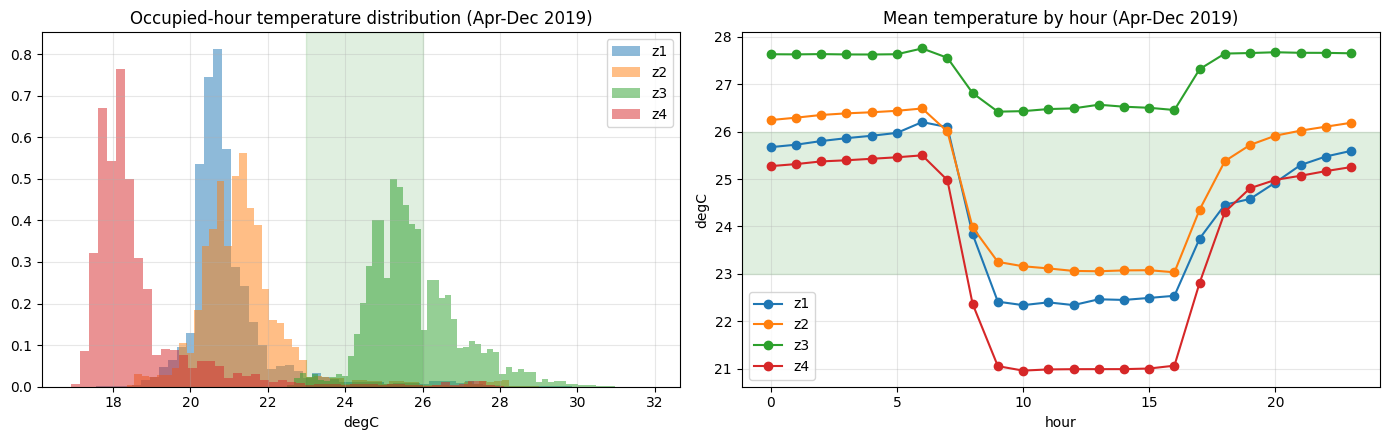

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for z in zone_ids:
    T = env[f'{z}_S1(degC)'].dropna()
    if len(T):
        axes[0].hist(T, bins=60, alpha=0.5, label=z, density=True)
axes[0].axvspan(LOW, HIGH, color='green', alpha=0.12)
axes[0].set_title('Occupied-hour temperature distribution (Apr-Dec 2019)')
axes[0].set_xlabel('degC'); axes[0].legend()

hourly_t = (df_all[df_all['Date'] >= '2019-04-01']
            .pivot_table(index='hour', values=temp_cols, aggfunc='mean'))
hourly_t.columns = [c.split('_')[0] for c in hourly_t.columns]
hourly_t.plot(ax=axes[1], marker='o')
axes[1].axhspan(LOW, HIGH, color='green', alpha=0.12)
axes[1].set_title('Mean temperature by hour (Apr-Dec 2019)'); axes[1].set_ylabel('degC')
plt.tight_layout(); plt.show()

In [40]:
# 13.4 Same months, different years: did the floor get colder while using more cooling?
occ_all = df_all[df_all['is_occupied']]
cmp_months = [7, 8, 9, 10, 11, 12]
yoy = []
for z in ['z1', 'z2']:
    for m in cmp_months:
        sub = occ_all[occ_all['month'] == m]
        r = {'zone': z, 'month': m}
        for y in [2018, 2019]:
            s = sub[sub['year'] == y]
            r[f'{y} temp'] = s[f'{z}_S1(degC)'].mean()
            r[f'{y} AC kW'] = s[[c for c in ac_cols if c.startswith(z + '_')]].sum(axis=1, min_count=1).mean()
        yoy.append(r)
yoy = pd.DataFrame(yoy).set_index(['zone', 'month'])
yoy['temp change'] = yoy['2019 temp'] - yoy['2018 temp']
yoy['AC kW change'] = yoy['2019 AC kW'] - yoy['2018 AC kW']
display(yoy.round(1))
print('Months with valid sensor data in BOTH years are the only comparable rows -')
print('the 2018 sensors stop in September, so Oct-Dec 2018 temps are NaN by design.')

2018 temp  2018 AC kW  2019 temp  2019 AC kW  temp change  AC kW change
zone month                                                                         
z1   7           23.4        27.9       20.7        30.0         -2.6           2.1
     8           23.5        27.8       20.9        28.6         -2.6           0.8
     9           23.4        27.5       20.9        25.8         -2.5          -1.8
     10           NaN        29.0       21.2        29.7          NaN           0.7
     11           NaN        27.8       21.1        27.1          NaN          -0.7
     12           NaN        27.5       21.1        25.3          NaN          -2.2
z2   7           24.0        29.2       21.9        28.2         -2.1          -1.0
     8           26.1        21.0       21.3        29.5         -4.9           8.4
     9           27.8        17.5       21.1        29.0         -6.8          11.5
     10           NaN        21.3       21.6        29.8          NaN           8.4
     11           NaN        20.6       20.7        28.6          NaN           8.1
     12           NaN        20.7       20.5        27.4          NaN           6.7

Months with valid sensor data in BOTH years are the only comparable rows -
the 2018 sensors stop in September, so Oct-Dec 2018 temps are NaN by design.


## 14. Findings

All figures below come from the cells above. 2018 covers 1 Jul – 31 Dec; 2019 is the full year.

### Data quality (Section 3)

* Both files are **complete 1-minute series**: 264,960 rows (2018) and 525,600 rows (2019), with
  zero missing minutes, zero duplicate timestamps and no corrupt rows.
* **Power columns are clean** (0.1–0.4 % missing) except the three large AC units, which lose
  5.7 % of 2019 overall — concentrated in **January–February 2019, where they are 28–42 % missing**.
  Those two months understate floor energy and are excluded from year-on-year comparisons.
* **Environment sensors are the weak point**: 61 % missing in 2018 and ~20 % in 2019. The pattern
  is a single long outage — sensors stop in **September 2018** and return in **March 2019**. Zone 4
  has **no sensor data at all in 2018**. Therefore all comfort analysis uses **Apr–Dec 2019**.
* `z2_AC11` and `z2_AC12` are **zero for 99 %+ of both years** — dead or unmetered, not efficient.
  `z2_AC13` and `z2_AC14` are off 92–99 % of the time. All four are excluded from per-unit work.

### Energy (Sections 6–7)

* **2019 floor energy: 240,975 kWh** (660 kWh/day); 2018 ran at 674 kWh/day, so on a per-day basis
  the floor was **2 % more efficient in 2019** — the apparent +94 % is only the longer file.
* End-use split is stable and cooling-dominated: **78.6 % cooling, 15.5 % lighting, 5.9 % plug**.
* By zone (2019): z1 103 MWh, z2 107 MWh, z4 23 MWh, z3 7 MWh. **Zone 2 grew 115 %** versus 2018
  on a raw basis and is the only zone whose per-day consumption rose materially — see the
  2018/2019 comparison below.

### When energy is used (Section 8)

* The weekday profile has a **sharp ramp at 07:00–08:00 and a drop after 17:00** in both years,
  which is what justifies the 08:00–16:59 occupancy proxy.
* **27.5 % of 2019 energy is used outside occupied hours** (16.9 % weekday off-hours, 10.5 %
  weekends and holidays), down from 31.3 % in 2018. For comparison, Floor 3 sits at about 15 %.
* Cooling **never reaches zero**: the floor's mean cooling demand between 22:00 and 05:00 is
  **5.9 kW**, including weekends and public holidays.

### Unit-level behaviour (Section 13)

* **Six small Zone 2 units — AC5 to AC10 — run at more than 60 % of their occupied load overnight**
  (several run *harder* at night than during the day). Together they used **31,771 kWh in 2019,
  13.2 % of the whole floor**. Adding AC2–AC4, which run at about 45 % of their day load overnight,
  the nine always-on units account for roughly 18 % of floor energy.
* These nine units operate as **three groups of three that swap over** — group A (AC2–AC4),
  group B (AC5, AC7, AC9) and group C (AC6, AC8, AC10) — with changeovers around **Sep 2018** and
  **Jul 2019**, and strong negative correlation between the groups. This is the signature of
  **duty/standby rotation on a continuously cooled space**, which is what a server or equipment
  room looks like. It is *not* evidence of a fault. The question for facilities is why **two**
  groups run simultaneously overnight rather than one.
* The large units behave correctly: `z1_AC1`, `z4_AC1` and `z2_AC1` are effectively off at night
  (0.4 %, 0 % and 2.9 % of their occupied load).

### Indoor environment and comfort (Sections 10 and 13.3)

* Occupied-hour means, Apr–Dec 2019, against a 23–26 °C band:

  | Zone | AC? | Mean temp | % below 23 °C | % in band | Overcooling degree-hours |
  |---|---|---|---|---|---|
  | z1 | yes | 21.0 °C | 93.7 % | 4.2 % | 3,277 |
  | z2 | yes | 21.4 °C | 93.5 % | 4.7 % | 2,805 |
  | z3 | **no** | 25.8 °C | 1.1 % | 65.7 % | 3 |
  | z4 | yes | 18.7 °C | 96.8 % | 1.7 % | 7,120 |

  **Zone 4 is the extreme case** at 18.7 °C with high humidity. The uncooled Zone 3 sits inside the
  comfort band two-thirds of the time, which makes it a useful control.
* **The floor got colder between 2018 and 2019 while using more cooling.** In Zone 2, Aug–Sep
  occupied temperature fell from 26.1 °C / 27.8 °C to 21.3 °C / 21.1 °C while the zone's mean AC
  demand rose by 8.4 kW and 11.5 kW. Same equipment, same season, so this is a usable natural
  experiment for estimating the cost of the lower setpoint. The caveat is that the sensors were
  offline and reinstalled during the gap, so a sensor change cannot be fully ruled out — but the
  independent rise in AC power supports a real control change.
* **Lux is measuring the lamps, not daylight**: midday illuminance is near zero whenever the
  lights are off. Any daylight-dimming analysis built on these columns would be circular.

### Anomalies (Section 12)

* Tukey fences and day-of-week z-scores agree: the largest negative outliers are **Thai public
  holidays** (5 Dec, 23 Oct, 27 Jul, Songkran) — expected behaviour, not faults, which is why the
  holiday calendar is in Section 4.
* The genuinely unexplained low period is **23 Jan – 12 Feb 2019**, which coincides with the large
  AC metering gap. It is a reporting artefact rather than a shutdown.

### What this supports for the project

1. **After-hours / 24-7 cooling** — 27.5 % of energy outside occupied hours, a 5.9 kW night
   cooling baseload, and nine rotating units carrying ~18 % of floor energy. Action: confirm the
   space's function with facilities, then either schedule the units or run one group instead of
   two. KPIs: night cooling baseload (kW) and off-hours share of energy (%).
2. **Overcooling** — 93–97 % of occupied minutes below 23 °C in the cooled zones, with Zone 4 at
   18.7 °C, and a 2018-versus-2019 comparison that shows what the warmer setpoint used to cost.
   Action: staged setpoint increase starting with Zone 4. KPIs: % of occupied minutes in band and
   weather-normalised cooling kWh per weekday.

**Still to add before the final submission:** outdoor Bangkok weather (not in CU-BEMS) to
normalise the cooling baseline, and a cited comfort standard to replace the placeholder 23–26 °C
band.

In [41]:
print('=' * 72)
print(f'{FLOOR} — key figures for the project slides')
print('=' * 72)
print(f"2019 floor energy            : {df19['floor_kWh'].sum():,.0f} kWh")
print(f"2019 cooling share           : {df19['cooling_kWh'].sum() / df19['floor_kWh'].sum() * 100:.1f}%")
print(f"Energy outside occupied hrs  : {(1 - df19.loc[df19['is_occupied'], 'floor_kWh'].sum() / df19['floor_kWh'].sum()) * 100:.1f}%")
print(f"Night cooling baseload       : {df19.loc[df19['is_night'], 'cooling_kW'].mean():.1f} kW")
print(f"Always-on AC units           : {len(always_on)} units, {kwh_always_on:,.0f} kWh in 2019")
print()
print('Occupied-hour comfort (Apr-Dec 2019):')
print(comfort[['mean temp', f'% below {LOW}C', f'% in {LOW}-{HIGH}C', 'overcooling degree-hours']].round(1))

Floor 2 — key figures for the project slides
2019 floor energy            : 240,975 kWh
2019 cooling share           : 78.6%
Energy outside occupied hrs  : 27.5%
Night cooling baseload       : 5.9 kW
Always-on AC units           : 6 units, 31,771 kWh in 2019

Occupied-hour comfort (Apr-Dec 2019):
      mean temp  % below 23.0C  % in 23.0-26.0C  overcooling degree-hours
zone                                                                     
z1         21.0           93.7              4.2                    3277.2
z2         21.4           93.5              4.7                    2804.8
z3         25.8            1.1             65.7                       2.6
z4         18.7           96.8              1.7                    7119.9
